# FracAtlas + HBFMID — EDA notebook
## Part A: image audit, de-duplication, leakage-safe splits · Part B: fixing class imbalance (weighted / focal loss, minority-class augmentation)
**CSE366 · fracture classification · Part A runs on CPU; Part B needs a GPU (Kaggle: Settings → Accelerator)**

Run all cells top to bottom. The notebook does five jobs:

| Step | What it does |
|---|---|
| 1–2 | Finds the datasets, inventories every file, builds labels / modality / split / source-family metadata |
| 3 | Decodes each image once (cached): hashes, quality features, tiny thumbnails |
| 4–5 | Coverage, class balance, quality, galleries, dataset shift |
| 6 | Exact **and** near-duplicate detection, grouped into leakage-safe families |
| 7–9 | Eligibility waterfall, grouped train/val/test split, low-label budgets, class weights |
| 10 | Augmentation policy (training-time only) with a visual preview |
| 11 | Summary, auto-generated findings, exports |

**Key rules baked in:** unknown is never "negative"; augmentation is applied *after* the split and only to training; near-duplicate families never straddle splits; HBFMID is kept as an external set and never mixed into training.

## 1 · Setup and settings
Paths are resolved in this order: environment variable → configured path → search under `/kaggle/input`. Change only the `SETTINGS` block if something needs adjusting.

In [1]:
import os, re, json, time, hashlib, platform, shutil, importlib.metadata, warnings
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageFile
from scipy.ndimage import laplace
from scipy.stats import wasserstein_distance
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings('ignore', category=FutureWarning)

# ------------------------------- SETTINGS -------------------------------
SEED = 42
DATASETS = {
    'FracAtlas': {'env': 'FRACATLAS_ROOT', 'tokens': ('fracatlas',),
                  'roots': ['/kaggle/input/datasets/arifulislamopi/fracatlas/FracAtlas']},
    'HBFMID':    {'env': 'HBFMID_ROOT', 'tokens': ('hbfmid', 'human bone fractures multi-modal'),
                  'roots': ['/kaggle/input/datasets/arifulislamopi/hbfmid/Human Bone Fractures Multi-modal Image Dataset (HBFMID)']},
}
OUT   = Path(os.environ.get('FRACTURE_OUT', '/kaggle/working/fracture_eda'))
CACHE = OUT.parent / '.fracture_eda_cache'      
WORKERS = min(8, max(1, os.cpu_count() or 2))
THUMB, TINY = 256, 32                            

ALLOW_TRUNCATED = True         
ASSUME_XRAY_IF_NOT_MRI = True  

# near-duplicate detection
NEAR_RADIUS = 2                
AUTO_GROUP_DIST, AUTO_GROUP_CORR = 1, 0.90   
REVIEW_MIN_CORR = 0.60         
GROUP_UNREVIEWED = True        
MAX_NEAR_PAIRS = 200_000
NEAR_REVIEW_CSV = None         

# splitting
MAKE_SPLITS = True
ALLOW_IMAGE_LEVEL_SPLIT = True 
BUDGET_FRACTIONS = [0.01, 0.05, 0.10, 0.25, 1.0]
BUDGET_SEEDS = [42, 123, 2026]
DISPLAY_GALLERIES = True
# ------------------------------------------------------------------------

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
SKIP_DIRS = {'masks', 'mask', 'annotations', '.ipynb_checkpoints', '__macosx'}
META = ['label', 'modality', 'is_augmented', 'patient_id', 'source_id', 'body_region', 'hospital',
        'split', 'sex', 'age', 'hardware', 'view', 'fracture_type', 'multiscan']
COLORS = {'FracAtlas': '#21618C', 'HBFMID': '#D17A22', 'Non-fracture': '#2A9D8F',
          'Fracture': '#C45566', 'Unknown': '#8A939E'}

ImageFile.LOAD_TRUNCATED_IMAGES = bool(ALLOW_TRUNCATED)
OUT.mkdir(parents=True, exist_ok=True); (OUT / 'figures').mkdir(exist_ok=True); CACHE.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 220, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})

FINDINGS, summary = [], {}
def note(level, msg):
    FINDINGS.append((level, msg)); print(f'[{level.upper()}] {msg}')
def export(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False)
def finish(fig, name, svg=True):
    fig.tight_layout()
    fig.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight')
    if svg: fig.savefig(OUT / 'figures' / f'{name}.svg', bbox_inches='tight')
    plt.show(); plt.close(fig)
def safe_rgb(im):
    try: im = ImageOps.exif_transpose(im)
    except Exception: pass
    return im.convert('RGB')
popcount = int.bit_count if hasattr(int, 'bit_count') else (lambda x: bin(x).count('1'))

def resolve_root(name):
    cfg = DATASETS[name]
    for p in [os.environ.get(cfg['env'])] + cfg['roots']:
        if p and Path(p).is_dir(): return Path(p).resolve()
    base = Path('/kaggle/input')
    if not base.is_dir():
        raise FileNotFoundError(f'{name}: no valid path. Attach the dataset or set env var {cfg["env"]}.')
    hits = []
    for d in base.rglob('*'):
        if d.is_dir() and any(t in d.name.lower() for t in cfg['tokens']):
            n = sum(1 for q in d.rglob('*') if q.suffix.lower() in IMG_EXT)
            if n: hits.append((n, len(d.parts), d))
    if not hits: raise FileNotFoundError(f'{name}: nothing found under /kaggle/input. Set DATASETS["{name}"]["roots"].')
    hits.sort(key=lambda t: (-t[0], -t[1]))
    if len(hits) > 1 and hits[0][:2] == hits[1][:2]:
        raise RuntimeError(f'{name}: ambiguous roots {[str(h[2]) for h in hits[:3]]}. Set the path explicitly.')
    print(f'{name}: auto-discovered {hits[0][2]}'); return hits[0][2].resolve()

versions = {}
for pkg in ['numpy', 'pandas', 'Pillow', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn']:
    try: versions[pkg] = importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError: versions[pkg] = 'n/a'
(OUT / 'run_config.json').write_text(json.dumps({'seed': SEED, 'python': platform.python_version(), 'packages': versions,
    'near_radius': NEAR_RADIUS, 'auto_group': [AUTO_GROUP_DIST, AUTO_GROUP_CORR], 'review_min_corr': REVIEW_MIN_CORR,
    'group_unreviewed': GROUP_UNREVIEWED, 'allow_image_level_split': ALLOW_IMAGE_LEVEL_SPLIT}, indent=2))
print('Output folder:', OUT, '| workers:', WORKERS)

Output folder: /kaggle/working/fracture_eda | workers: 4


## 2 · Inventory and metadata
Every file under each dataset root is counted. Images are kept; label / annotation / README files are kept aside for metadata.

In [2]:
SPLIT_ALIASES = {'train': 'train', 'training': 'train', 'valid': 'valid', 'val': 'valid',
                 'validation': 'valid', 'test': 'test', 'testing': 'test'}
POS_DIRS = {'fractured', 'fracture', 'fractures', 'positive', 'with fracture', 'fracture positive'}
NEG_DIRS = {'non fractured', 'nonfractured', 'not fractured', 'no fracture', 'normal', 'negative',
            'without fracture', 'unfractured'}
NEG_CLASS = re.compile(r'normal|no[ _-]?fracture|non[ _-]?fractur|healthy|negative', re.I)
ASSUMPTIONS = []

def scan(name, root):
    rows, other, side = [], Counter(), []
    for p in sorted(root.rglob('*')):
        if not p.is_file(): continue
        rel = p.relative_to(root); parts = {x.lower() for x in rel.parts[:-1]}
        ext = p.suffix.lower()
        if ext in IMG_EXT and not (parts & SKIP_DIRS):
            st = p.stat()
            rows.append({'dataset': name, 'path': str(p), 'relative_path': rel.as_posix(), 'filename': p.name,
                         'suffix': ext, 'bytes': st.st_size})
        else:
            other[ext or '(none)'] += 1
            if ext in {'.txt', '.json', '.xml', '.yaml', '.yml', '.csv', '.md'}: side.append(p)
    if not rows: raise ValueError(f'{name}: no images under {root}')
    df = pd.DataFrame(rows)
    for c in META: df[c] = pd.Series([pd.NA] * len(df), dtype=object)
    top = df.relative_path.map(lambda r: '/'.join(r.split('/')[:-1][:2]) or '(root)').value_counts()
    print(f'\n{name}: {len(df):,} images | other files: {dict(other)}')
    print('  image folders:', {k: int(v) for k, v in top.head(12).items()})
    for p in side:                                   
        if p.name.lower().startswith('readme'):
            print(f'  --- {p.name} (first lines) ---')
            for line in p.read_text(errors='ignore').splitlines()[:14]: print('   ', line[:140])
    return df, side

def fill(df, col, values):
    df[col] = df[col].where(df[col].notna(), pd.Series(values, index=df.index, dtype=object))

def folder_label(rel):
    parts = [re.sub(r'[^a-z0-9]+', ' ', x.lower()).strip() for x in rel.split('/')[:-1]]
    hits = [1 if x in POS_DIRS else 0 for x in parts if x in POS_DIRS or x in NEG_DIRS]
    return hits[-1] if hits and len(set(hits)) == 1 else pd.NA

def one_hot_to_text(frame, cols, joiner='+'):
    cols = [c for c in cols if c in frame]
    if not cols: return pd.Series([pd.NA] * len(frame), index=frame.index, dtype=object)
    v = frame[cols].apply(pd.to_numeric, errors='coerce').fillna(0)
    return v.apply(lambda r: joiner.join(c for c in cols if r[c] == 1) or pd.NA, axis=1)

def build_fracatlas(df, side):
    df['modality'] = 'xray'; df['is_augmented'] = 0
    ASSUMPTIONS.append(('FracAtlas', 'is_augmented = 0, modality = xray', 'release describes original X-rays'))
    folder = df.relative_path.map(folder_label)
    meta = None
    for p in side:
        if p.suffix.lower() != '.csv': continue
        try: cols = {c.strip().lower() for c in pd.read_csv(p, nrows=0).columns}
        except Exception: continue
        if {'image_id', 'fractured'} <= cols:
            meta = pd.read_csv(p); meta.columns = [c.strip().lower() for c in meta.columns]
            print(f'  FracAtlas metadata CSV: {p.name} columns={list(meta.columns)}'); break
    if meta is None:
        note('warn', 'FracAtlas: metadata CSV (image_id + fractured) not found; labels from folder names only.')
        fill(df, 'label', folder); df['label_source'] = np.where(folder.notna(), 'folder', 'unknown'); return
    dup_names = df.filename.duplicated(keep=False)
    if dup_names.any():
        export(df.loc[dup_names, ['relative_path', 'filename', 'bytes']].sort_values('filename'), 'duplicate_filenames')
        note('warn', f'FracAtlas: {int(dup_names.sum())} files share a filename across folders (duplicate_filenames.csv). '
                     'Each is labelled only if its folder agrees with the CSV; otherwise the label stays unknown and the image is excluded.')
    meta['filename'] = meta['image_id'].astype(str).map(lambda s: Path(s).name)
    meta = meta.drop_duplicates('filename')
    m = df[['filename']].merge(meta, on='filename', how='left').set_index(df.index)
    csv_label = pd.to_numeric(m['fractured'], errors='coerce')
    if csv_label.isna().all():
        csv_label = m['fractured'].astype(str).str.lower().map({'yes': 1, 'no': 0, 'true': 1, 'false': 0})
    f_num = pd.to_numeric(folder, errors='coerce'); c_num = pd.to_numeric(csv_label, errors='coerce')
    bad = f_num.notna() & c_num.notna() & (f_num != c_num)
    if bad.any():
        export(df.loc[bad, ['relative_path']].assign(folder_label=folder[bad], csv_label=csv_label[bad]), 'label_source_conflicts')
        note('warn', f'FracAtlas: {int(bad.sum())} images where folder label and CSV label disagree (label_source_conflicts.csv); left unlabeled and excluded.')
    lab = c_num.where(c_num.notna(), f_num).where(~bad, np.nan)
    fill(df, 'label', lab)
    df['label_source'] = np.where(bad, 'unresolved', np.where(csv_label.notna(), 'csv', np.where(folder.notna(), 'folder', 'unknown')))
    reg = one_hot_to_text(m, ['hand', 'leg', 'hip', 'shoulder'])
    if 'mixed' in m: reg = reg.where(pd.to_numeric(m['mixed'], errors='coerce').fillna(0) != 1, 'mixed')
    fill(df, 'body_region', reg.map(lambda x: 'mixed' if isinstance(x, str) and '+' in x else x))
    fill(df, 'view', one_hot_to_text(m, ['frontal', 'lateral', 'oblique']))
    for col, name in [('hardware', 'hardware'), ('multiscan', 'multiscan')]:
        if col in m: fill(df, name, pd.to_numeric(m[col], errors='coerce').map({1: 'yes', 0: 'no'}))

def load_class_names(side):
    for p in side:
        if p.suffix.lower() in {'.yaml', '.yml'}:
            try:
                import yaml
                names = yaml.safe_load(p.read_text()).get('names')
                if isinstance(names, dict): names = [names[k] for k in sorted(names)]
                if names: return [str(n) for n in names]
            except Exception:
                m = re.search(r'names:\s*\[(.*?)\]', p.read_text(errors='ignore'), re.S)
                if m: return [x.strip(' \'"') for x in m.group(1).split(',')]
    return []

def image_key(rel):
    pp = Path(rel).parent
    if pp.name.lower() == 'images': pp = pp.parent
    return (pp.as_posix(), Path(rel).stem)

def build_hbfmid(df, root, side):
    low = df.relative_path.str.lower()
    parts = low.map(lambda r: r.split('/')[:-1])
    fill(df, 'split', parts.map(lambda ps: next((SPLIT_ALIASES[x] for x in ps if x in SPLIT_ALIASES), pd.NA)))
    base = df.filename.str.extract(r'^(.*?)\.rf\.', expand=False)
    fill(df, 'source_id', df['split'].astype('string').fillna('nosplit') + '/' + base)   # scoped by split: file numbers repeat across originals
    is_mri = low.str.contains('mri'); is_xr = low.str.contains(r'x[-_ ]?ray|radiograph')
    df['modality'] = np.where(is_mri, 'mri', np.where(is_xr | ASSUME_XRAY_IF_NOT_MRI, 'xray', None))
    df['modality_basis'] = np.where(is_mri | is_xr, 'filename/path token', 'by elimination (verify)')
    df['family_size'] = df.groupby('source_id').filename.transform('size')
    aug = df['split'].map({'train': 1, 'valid': 0, 'test': 0})
    fill(df, 'is_augmented', aug)
    ASSUMPTIONS.append(('HBFMID', 'source_id = split + text before ".rf."',
                        'Roboflow naming; the number prefix is NOT unique (e.g. "101_jpg" labels different images), so it is only trusted within one split'))
    ASSUMPTIONS.append(('HBFMID', 'train split = augmented, valid/test = original', 'Roboflow augments the training split only; check README.roboflow.txt'))
    ASSUMPTIONS.append(('HBFMID', 'non-MRI images = X-ray' if ASSUME_XRAY_IF_NOT_MRI else 'non-MRI = unknown', 'compare with published 510 X-ray / 131 MRI originals'))
    # labels: YOLO label files next to the images
    names = load_class_names(side); yolo = {}
    for p in side:
        if p.suffix.lower() == '.txt' and p.parent.name.lower() == 'labels':
            ids = set()
            for line in p.read_text(errors='ignore').split('\n'):
                t = line.split()
                if t:
                    try: ids.add(int(float(t[0])))
                    except ValueError: pass
            yolo[(p.parent.parent.relative_to(root).as_posix(), p.stem)] = ids
    print(f'  HBFMID class names: {names or "none found"} | YOLO label files: {len(yolo)}')
    if yolo:
        keys = df.relative_path.map(image_key)
        found = keys.map(lambda k: k in yolo)
        def lab(k):
            ids = yolo.get(k)
            if ids is None: return pd.NA
            if not ids: return 0
            return 0 if names and all(i < len(names) and NEG_CLASS.search(names[i]) for i in ids) else 1
        def ftype(k):
            ids = yolo.get(k) or set()
            return ';'.join(sorted({names[i] if i < len(names) else str(i) for i in ids})) or pd.NA
        fill(df, 'label', keys.map(lab)); fill(df, 'fracture_type', keys.map(ftype))
        ASSUMPTIONS.append(('HBFMID', 'label = 1 if the YOLO file has a box, 0 if the file is empty',
                            'empty label file = no annotated fracture; verify against the dataset paper'))
        note('info', f'HBFMID: {int(found.sum()):,}/{len(df):,} images matched to a YOLO label file.')
    else:
        fill(df, 'label', df.relative_path.map(folder_label))
        note('warn', 'HBFMID: no YOLO label files found. Check the folder tree printed above; labels stay unknown.')

def finalize(df):
    for c in ['label', 'is_augmented']:
        v = pd.to_numeric(df[c], errors='coerce')
        if (v.dropna().isin([0, 1]) == False).any(): raise ValueError(f'{c} must be 0/1')
        df[c] = v.astype('Int64')
    df['modality'] = df['modality'].astype('string').str.strip().str.lower()
    for c in ['patient_id', 'source_id', 'body_region', 'hospital', 'split', 'sex', 'view', 'hardware', 'fracture_type', 'multiscan']:
        df[c] = df[c].astype('string').str.strip().replace('', pd.NA)
    df['age'] = pd.to_numeric(df['age'], errors='coerce')
    return df

frames, ROOTS = [], {}
for name in DATASETS:
    root = resolve_root(name); ROOTS[name] = root
    if root == OUT.resolve() or root in OUT.resolve().parents: raise ValueError('OUT must be outside the image root')
    df, side = scan(name, root)
    (build_fracatlas(df, side) if name == 'FracAtlas' else build_hbfmid(df, root, side))
    frames.append(finalize(df))
inventory = pd.concat(frames, ignore_index=True)
if inventory.path.duplicated().any(): raise ValueError('dataset roots overlap')
export(inventory, 'file_inventory')
export(inventory[['dataset', 'relative_path'] + META].rename(columns={'relative_path': 'path'}), 'metadata_to_review')
display(pd.DataFrame(ASSUMPTIONS, columns=['dataset', 'assumption', 'basis']))
display(inventory.groupby('dataset').agg(images=('path', 'size'), MB=('bytes', lambda x: round(x.sum() / 1e6, 1))))


FracAtlas: 4,085 images | other files: {'.json': 2, '.xml': 4083, '.txt': 4084, '.csv': 4, '.ipynb': 2}
  image folders: {'images/Non_fractured': 3366, 'images/Fractured': 719}
  FracAtlas metadata CSV: dataset.csv columns=['image_id', 'hand', 'leg', 'hip', 'shoulder', 'mixed', 'hardware', 'multiscan', 'fractured', 'fracture_count', 'frontal', 'lateral', 'oblique']
[WARN] FracAtlas: 4 files share a filename across folders (duplicate_filenames.csv). Each is labelled only if its folder agrees with the CSV; otherwise the label stays unknown and the image is excluded.
[WARN] FracAtlas: 2 images where folder label and CSV label disagree (label_source_conflicts.csv); left unlabeled and excluded.

HBFMID: 1,539 images | other files: {'.txt': 1540, '.yaml': 1}
  image folders: {'Bone Fractures Detection/train': 1347, 'Bone Fractures Detection/valid': 128, 'Bone Fractures Detection/test': 64}
  --- README.roboflow.txt (first lines) ---
    
    Bon Fracture Detection  - v2 2023-10-07 8:58pm
  

,dataset,assumption,basis
0,FracAtlas,"is_augmented = 0, modality = xray",release describes original X-rays
1,HBFMID,"source_id = split + text before "".rf.""",Roboflow naming; the number prefix is NOT uniq...
2,HBFMID,"train split = augmented, valid/test = original",Roboflow augments the training split only; che...
3,HBFMID,non-MRI images = X-ray,compare with published 510 X-ray / 131 MRI ori...
4,HBFMID,"label = 1 if the YOLO file has a box, 0 if the...",empty label file = no annotated fracture; veri...


,images,MB
dataset,,
FracAtlas,4085,339.5
HBFMID,1539,41.2


## 3 · Cached parallel image audit

In [3]:
CACHE_VERSION = 'audit-v2'
def sha_file(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()

def audit(path):
    try:
        bh = sha_file(path)
        cache = CACHE / (hashlib.sha256(f'{CACHE_VERSION}|{path}|{bh}|{THUMB}|{TINY}'.encode()).hexdigest() + '.json')
        if cache.exists(): return json.loads(cache.read_text())
        with Image.open(path) as im:
            im.load()
            mode, frames_n = im.mode, getattr(im, 'n_frames', 1)
            rgb = safe_rgb(im)
        w, h = rgb.size; full = rgb.convert('L')
        small = full.copy(); small.thumbnail((THUMB, THUMB), Image.Resampling.LANCZOS)
        a = np.asarray(small, dtype=np.float32) / 255.
        hist = np.histogram(a, bins=64, range=(0, 1))[0].astype(float); pr = hist[hist > 0] / hist.sum()
        dh = np.asarray(full.resize((9, 8), Image.Resampling.LANCZOS)); bits = (dh[:, 1:] > dh[:, :-1]).ravel()
        edge = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
        res = dict(path=path, valid=True, error='', width=w, height=h, aspect=w / h, mode=mode, frames=frames_n,
                   high_bit_depth=bool(mode.startswith('I') or mode == 'F'), sha256=bh,
                   pixel_sha256=hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest(),
                   dhash=f'{int("".join(map(str, bits.astype(int))), 2):016x}',
                   brightness=float(a.mean()), contrast=float(a.std()), entropy=float(-(pr * np.log2(pr)).sum()),
                   blur_score=float(laplace(a).var()), dark_fraction=float((a <= .02).mean()),
                   bright_fraction=float((a >= .98).mean()), border_mean=float(edge.mean()),
                   thumbnail_pixels=int(a.size), intensity_sum=float(a.sum()), intensity_sq_sum=float((a * a).sum()),
                   tiny=np.asarray(full.resize((TINY, TINY), Image.Resampling.BILINEAR), dtype=np.uint8).ravel().tolist())
        cache.write_text(json.dumps(res)); return res
    except Exception as e:
        return dict(path=path, valid=False, error=f'{type(e).__name__}: {str(e)[:160]}')

t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    rows = list(tqdm(pool.map(audit, inventory.path.tolist()), total=len(inventory), desc='Auditing images'))
tiny_map = {r['path']: np.asarray(r.pop('tiny'), dtype=np.float32) for r in rows if r.get('valid')}
df = inventory.merge(pd.DataFrame(rows), on='path', validate='one_to_one')
export(df.loc[~df.valid, ['dataset', 'relative_path', 'error']], 'unreadable_images')
good = df.loc[df.valid].reset_index(drop=True)
if good.empty: raise ValueError('No decodable images; see unreadable_images.csv')
good['class'] = good.label.map({0: 'Non-fracture', 1: 'Fracture'}).fillna('Unknown')
print(f'Audit {time.perf_counter() - t0:.1f}s | readable {len(good):,} | unreadable {int((~df.valid).sum())}')
if (~df.valid).any():
    bad = df.loc[~df.valid]
    display(bad.groupby(['dataset', bad.error.str[:90]]).size().rename('files').reset_index())
    cls = bad.assign(c=bad.label.map({0: 'Non-fracture', 1: 'Fracture'}).fillna('Unknown')).groupby(['dataset', 'c']).size()
    cls = {f'{k[0]}/{k[1]}': int(v) for k, v in cls.items()}
    note('warn', f'{int((~df.valid).sum())} unreadable images ({cls}). Unreadable images are excluded from every later step; '
                 'if the errors say "truncated" make sure ALLOW_TRUNCATED=True and rerun.')
summary.update(scanned=len(df), readable=len(good), unreadable=int((~df.valid).sum()))

Auditing images:   0%|          | 0/5624 [00:00<?, ?it/s]

Audit 113.9s | readable 5,624 | unreadable 0


## 4 · Coverage, class balance and image quality
*Missing is not negative.* Coverage shows which metadata fields actually exist; Wilson intervals are descriptive and image-level (dependence between images makes them optimistic).

,label,modality,is_augmented,patient_id,source_id,body_region,hospital,split,sex,age,hardware,view,fracture_type,multiscan
dataset,,,,,,,,,,,,,,
FracAtlas,100.0,100.0,100.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,100.0
HBFMID,100.0,100.0,100.0,0.0,100.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,99.8,0.0


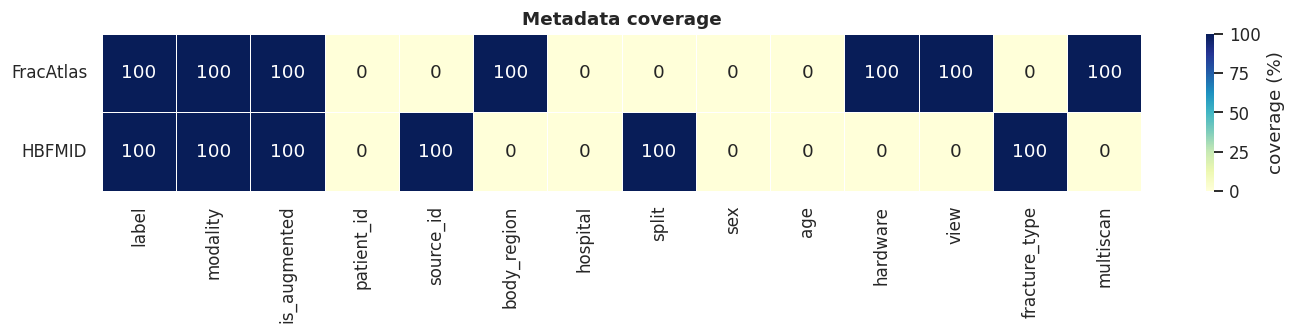

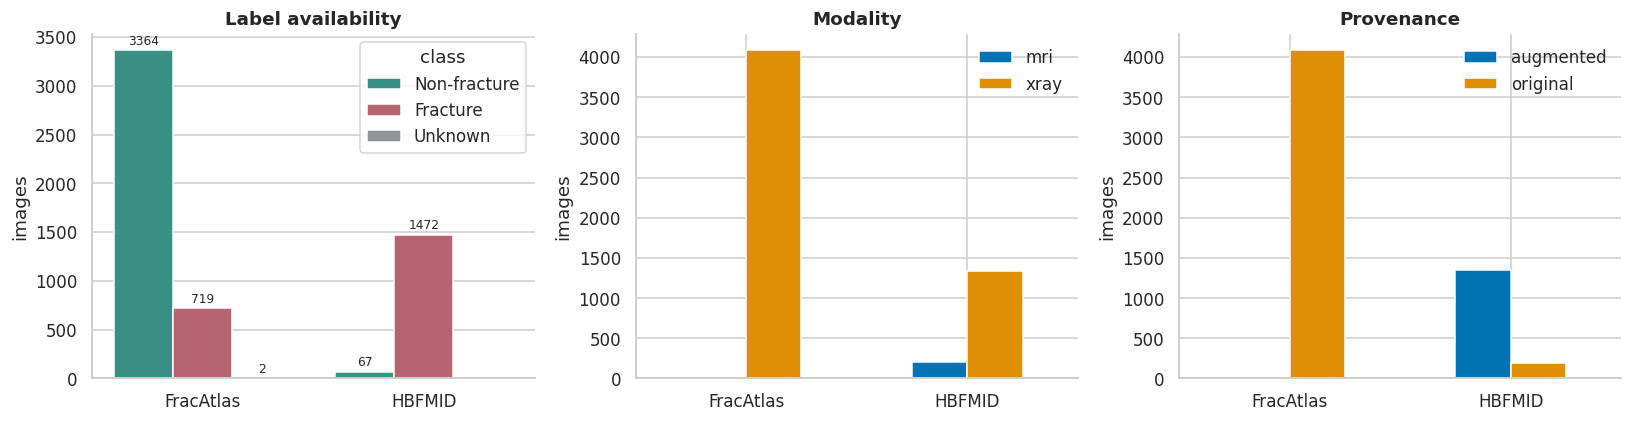

,dataset,labeled,positive,negative,prevalence,wilson_low,wilson_high,majority_class_accuracy
0,FracAtlas,4083,719,3364,0.1761,0.1647,0.1881,0.8239
1,HBFMID,1539,1472,67,0.9565,0.9451,0.9656,0.9565


[INFO] FracAtlas: prevalence 17.6%; use class weights / balanced sampling (a majority guess already scores 82.4%).


In [4]:
cov = df.groupby('dataset')[META].agg(lambda x: 100 * x.notna().mean()).apply(pd.to_numeric).astype('float64').round(1)
display(cov)
fig, ax = plt.subplots(figsize=(13, 3.2))
sns.heatmap(cov, annot=True, fmt='.0f', cmap='YlGnBu', vmin=0, vmax=100, linewidths=.4, linecolor='white',
            cbar_kws={'label': 'coverage (%)'}, ax=ax)
ax.set(title='Metadata coverage', ylabel=''); ax.tick_params(axis='y', rotation=0); finish(fig, '01_metadata_coverage')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cls = good.groupby(['dataset', 'class']).size().rename('n').reset_index()
sns.barplot(data=cls, x='dataset', y='n', hue='class', hue_order=['Non-fracture', 'Fracture', 'Unknown'],
            palette=COLORS, ax=axes[0])
for c in axes[0].containers: axes[0].bar_label(c, fmt='%.0f', fontsize=8, padding=2)
axes[0].set(title='Label availability', xlabel='', ylabel='images')
for ax, c in zip(axes[1:], ['modality', 'is_augmented']):
    vals = good[c].astype('string').fillna('unknown')
    if c == 'is_augmented': vals = vals.replace({'0': 'original', '1': 'augmented'})
    tab = pd.crosstab(good.dataset, vals)
    tab.plot.bar(ax=ax, rot=0, color=sns.color_palette('colorblind', len(tab.columns)))
    ax.set(title={'modality': 'Modality', 'is_augmented': 'Provenance'}[c], xlabel='', ylabel='images'); ax.legend(frameon=False)
finish(fig, '02_labels_modality_provenance')

bal = []
for name, g in good.groupby('dataset'):
    y = g.label.dropna().astype(int); n, k = len(y), int(y.sum())
    if n:
        z = 1.96; ctr = (k / n + z * z / (2 * n)) / (1 + z * z / n)
        half = z * np.sqrt(k / n * (1 - k / n) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        bal.append(dict(dataset=name, labeled=n, positive=k, negative=n - k, prevalence=round(k / n, 4),
                        wilson_low=round(ctr - half, 4), wilson_high=round(ctr + half, 4),
                        majority_class_accuracy=round(max(k, n - k) / n, 4)))
bal = pd.DataFrame(bal); export(bal, 'class_balance'); display(bal)
for r in bal.itertuples():
    if r.positive in (0, r.labeled):
        note('warn', f'{r.dataset}: all labeled images are one class -> AUROC/specificity are not estimable; report sensitivity only.')
    elif r.prevalence < .3:
        note('info', f'{r.dataset}: prevalence {r.prevalence:.1%}; use class weights / balanced sampling (a majority guess already scores {r.majority_class_accuracy:.1%}).')

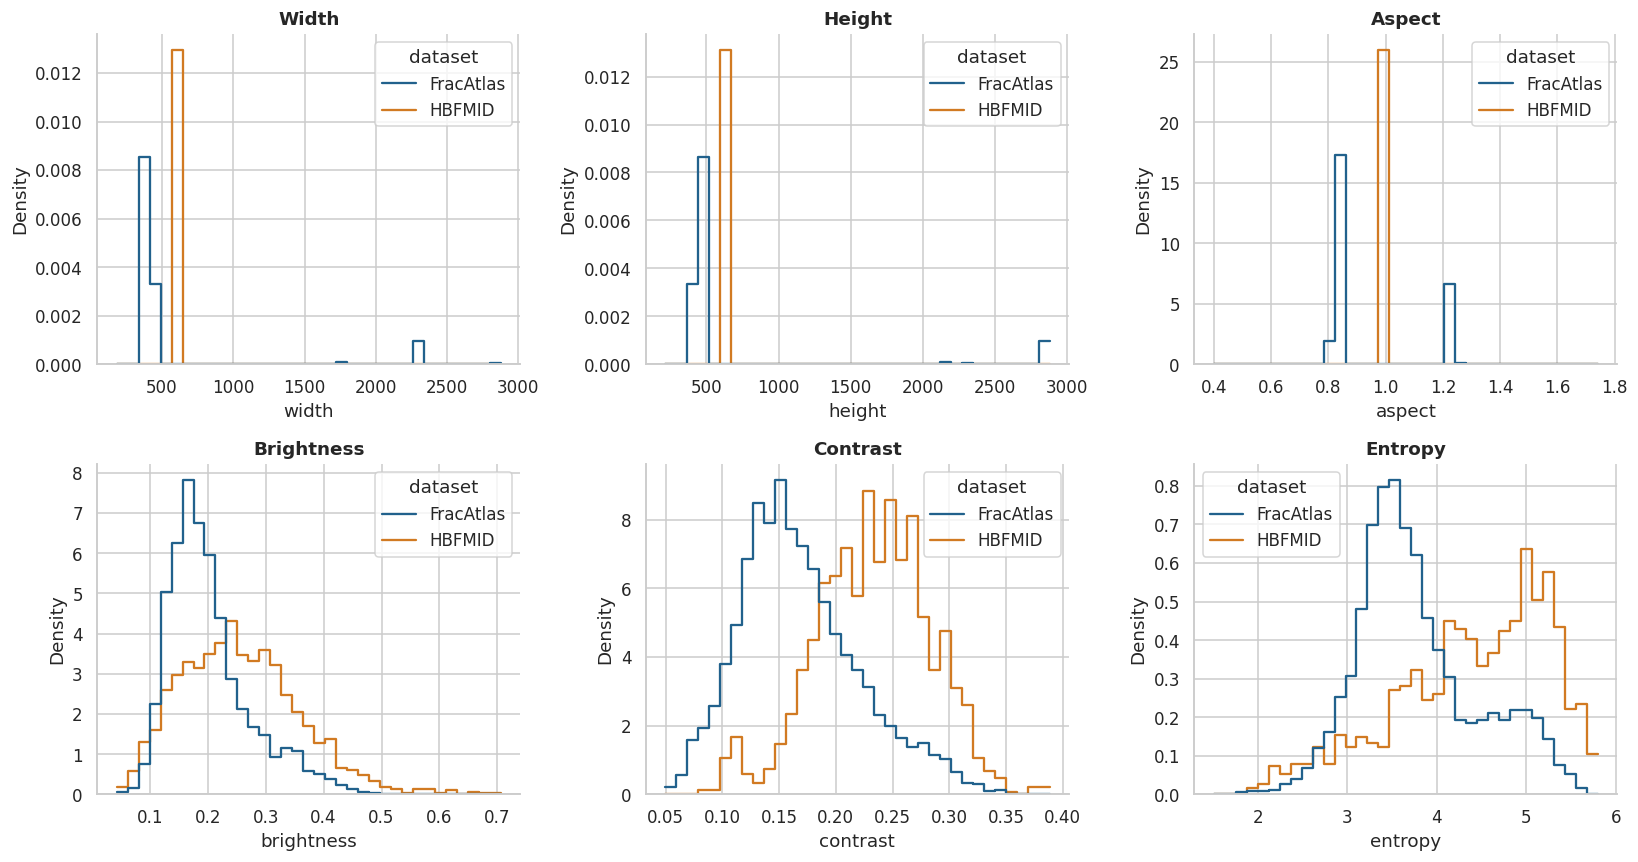

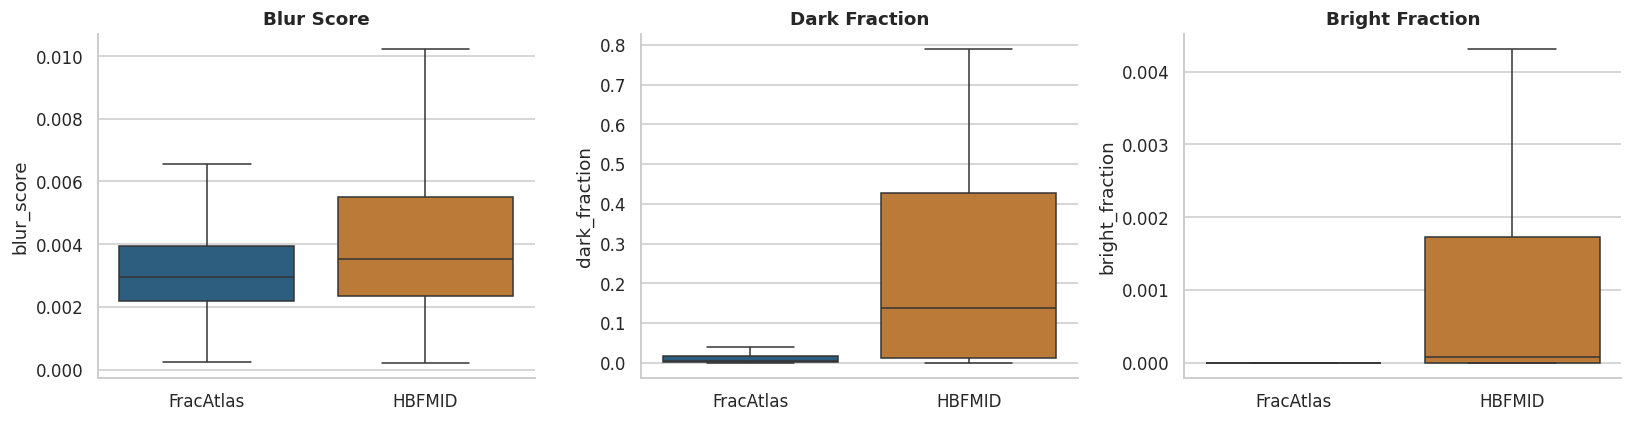

Flags are for review only; subtle fractures can look "blurry". Nothing is deleted automatically.


,small_image,near_constant,needs_decode_review,low_sharpness_1pct
dataset,,,,
FracAtlas,0,0,0,41
HBFMID,0,0,0,16


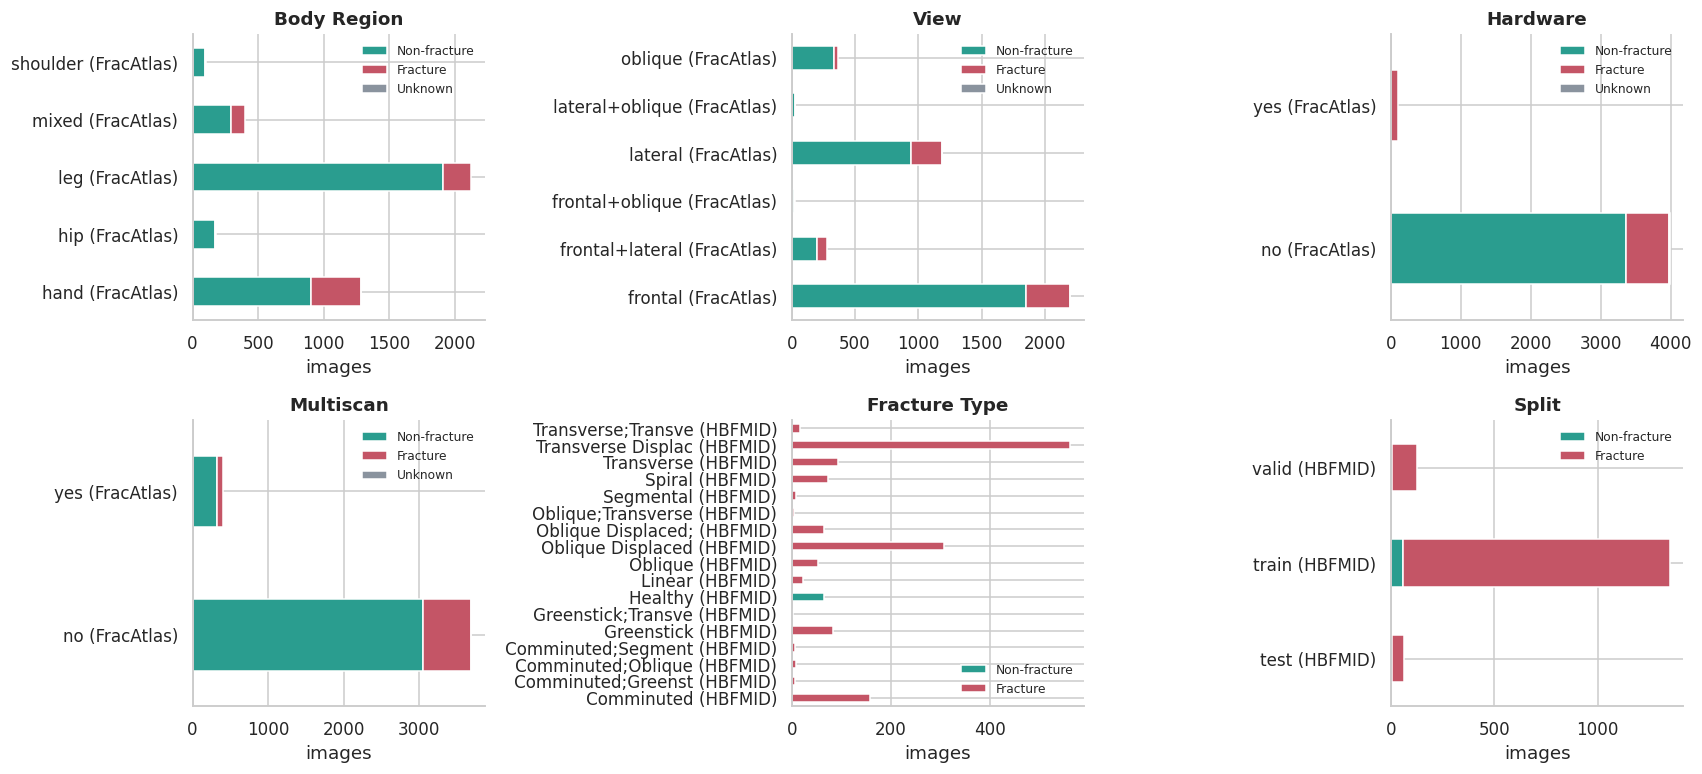

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), ['width', 'height', 'aspect', 'brightness', 'contrast', 'entropy']):
    sns.histplot(data=good, x=c, hue='dataset', palette=COLORS, element='step', fill=False, stat='density',
                 common_norm=False, bins=35, ax=ax); ax.set_title(c.title())
finish(fig, '03_resolution_intensity')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['blur_score', 'dark_fraction', 'bright_fraction']):
    sns.boxplot(data=good, x='dataset', y=c, hue='dataset', palette=COLORS, showfliers=False, ax=ax, legend=False)
    ax.set_title(c.replace('_', ' ').title()); ax.set_xlabel('')
finish(fig, '04_quality_distributions')

q = good[['dataset', 'path', 'width', 'height', 'frames', 'high_bit_depth', 'contrast', 'blur_score']].copy()
q['small_image'] = (q.width < 128) | (q.height < 128)
q['near_constant'] = q.contrast < .01
q['needs_decode_review'] = q.high_bit_depth | (q.frames > 1)
q['low_sharpness_1pct'] = q.blur_score < q.groupby('dataset').blur_score.transform(lambda x: x.quantile(.01))
export(q, 'quality_flags')
print('Flags are for review only; subtle fractures can look "blurry". Nothing is deleted automatically.')
display(q.groupby('dataset')[['small_image', 'near_constant', 'needs_decode_review', 'low_sharpness_1pct']].sum())

cols = [c for c in ['body_region', 'view', 'hardware', 'multiscan', 'fracture_type', 'split'] if good[c].notna().any()]
if cols:
    nc = 3; nr = int(np.ceil(len(cols) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(5.2 * nc, 3.6 * nr), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, c in zip(axes.ravel(), cols):
        ax.axis('on'); sub = good[good[c].notna()]
        tab = pd.crosstab(sub[c].astype(str).str[:18] + ' (' + sub.dataset + ')', sub['class'])
        tab = tab[[x for x in ['Non-fracture', 'Fracture', 'Unknown'] if x in tab.columns]]
        tab.plot.barh(stacked=True, ax=ax, color=[COLORS[x] for x in tab.columns])
        ax.set(title=c.replace('_', ' ').title(), ylabel='', xlabel='images'); ax.legend(frameon=False, fontsize=8)
    finish(fig, '05_metadata_by_class')

## 5 · Label sanity check against bounding boxes (FracAtlas COCO, if present)
A fractured image should normally have at least one box. Disagreements are **exported for review, never relabelled automatically**. Skipped silently-free: the cell prints why if no COCO file is found.

COCO file: COCO_fracture_masks.json | boxes 924 (invalid 0)


has_box,0,1
label,,
0,3364,0
1,0,719


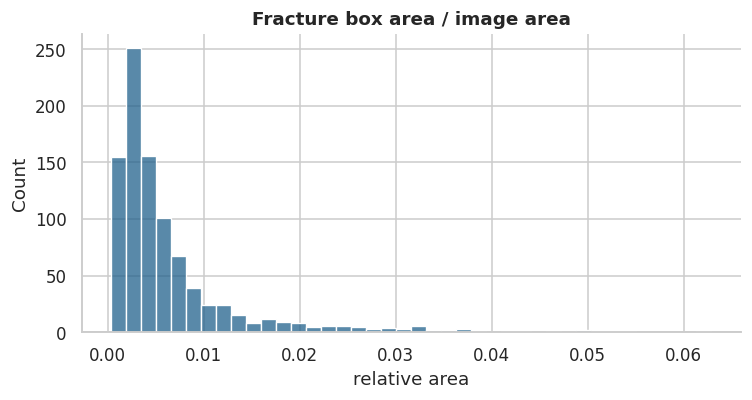

In [6]:
def find_coco(root):
    for p in sorted(root.rglob('*.json')):
        if p.stat().st_size > 300e6: continue
        try: obj = json.loads(p.read_text())
        except Exception: continue
        if isinstance(obj, dict) and {'images', 'annotations'} <= obj.keys(): return p, obj
    return None, None

coco_path, coco = find_coco(ROOTS['FracAtlas'])
good['has_box'] = pd.NA
if coco is None:
    print('No COCO annotation JSON found under the FracAtlas root; box check skipped (not verified).')
else:
    imgs = {i['id']: i for i in coco['images']}; boxes = []
    for a in coco['annotations']:
        r = imgs.get(a.get('image_id')); b = a.get('bbox') or []
        if r is None or len(b) != 4: continue
        W, H = r.get('width'), r.get('height')
        ok = bool(np.isfinite(b).all() and b[2] > 0 and b[3] > 0 and b[0] >= 0 and b[1] >= 0 and W and H
                  and b[0] + b[2] <= W + 1 and b[1] + b[3] <= H + 1)
        boxes.append(dict(file=Path(r['file_name']).name, valid=ok, rel_area=b[2] * b[3] / (W * H) if ok else np.nan))
    boxes = pd.DataFrame(boxes)
    with_box = set(boxes.loc[boxes.valid, 'file'])
    fa = good.dataset.eq('FracAtlas')
    good.loc[fa, 'has_box'] = good.loc[fa, 'filename'].isin(with_box).astype(int)
    chk = good.loc[fa & good.label.notna()].copy(); chk['has_box'] = chk.has_box.astype(int)
    print(f'COCO file: {coco_path.name} | boxes {len(boxes):,} (invalid {int((~boxes.valid).sum())})')
    display(pd.crosstab(chk.label.rename('label'), chk.has_box.rename('has_box')))
    dis = chk[chk.label != chk.has_box]
    export(dis[['relative_path', 'label', 'has_box']], 'label_vs_box_disagreements')
    if len(dis): note('warn', f'{len(dis)} FracAtlas images where label and box presence disagree (see label_vs_box_disagreements.csv).')
    if boxes.valid.any():
        fig, ax = plt.subplots(figsize=(7, 3.8)); sns.histplot(boxes.loc[boxes.valid, 'rel_area'], bins=40, color=COLORS['FracAtlas'], ax=ax)
        ax.set(title='Fracture box area / image area', xlabel='relative area'); finish(fig, '06_box_scale')

## 6 · Exact and near duplicates → leakage-safe families
1. **Exact**: identical bytes or identical decoded pixels. Copies with *conflicting labels* are exported and later removed.
2. **Near**: dHash candidates (radius `NEAR_RADIUS`) are verified with a second signal, the correlation of 32×32 thumbnails. Dark X-rays hash alike even when they are different patients, so the hash alone is too coarse.
   * `auto_group` – tiny hash distance **and** high correlation → same family.
   * `review` – plausible but weaker → grouped too by default (`GROUP_UNREVIEWED`) because leaking is worse than over-grouping; mark rows `distinct` in `near_duplicate_review.csv` to release them.
   * `distinct_auto` – ignored.
3. Families are merged transitively together with HBFMID `source_id` and any real patient IDs → `group_id`. A split must keep each `group_id` in one place.

In [7]:
# ---- exact duplicates
ex = []
for col in ['sha256', 'pixel_sha256']:
    d = good[good.duplicated(col, keep=False)]
    if len(d): ex.append(d[['dataset', 'relative_path', 'label', 'split', col]].rename(columns={col: 'hash'}).assign(type=col))
exact = pd.concat(ex, ignore_index=True) if ex else pd.DataFrame(columns=['dataset', 'relative_path', 'label', 'split', 'hash', 'type'])
export(exact, 'exact_duplicates')
redundant = len(good) - good.pixel_sha256.nunique()
conf_ids = good.groupby('pixel_sha256').label.nunique().loc[lambda s: s > 1].index
conflicts = good[good.pixel_sha256.isin(conf_ids)]
export(conflicts[['dataset', 'relative_path', 'label', 'pixel_sha256']], 'exact_label_conflicts')
print(f'Exact: {len(exact)} duplicate records, {redundant} redundant copies | label-conflict records: {len(conflicts)}')
by_ds = good.groupby('dataset').pixel_sha256.agg(lambda s: len(s) - s.nunique())
note('info', f'redundant exact copies per dataset: { {k: int(v) for k, v in by_ds.items()} }')
if len(conflicts): note('warn', f'{len(conflicts)} images share pixels with images of the OPPOSITE label (label noise); they are removed from the cohort.')

# ---- near duplicates: BK-tree on dHash, verified by thumbnail correlation
class BKTree:
    def __init__(self): self.root = None
    def add(self, v, i):
        if self.root is None: self.root = [v, [i], {}]; return
        node = self.root
        while True:
            d = popcount(v ^ node[0])
            if d == 0: node[1].append(i); return
            if d not in node[2]: node[2][d] = [v, [i], {}]; return
            node = node[2][d]
    def query(self, v, r):
        stack = [self.root] if self.root else []
        while stack:
            nv, ids, ch = stack.pop(); d = popcount(v ^ nv)
            if d <= r:
                for i in ids: yield i, d
            stack.extend(c for e, c in ch.items() if d - r <= e <= d + r)

H = [int(h, 16) for h in good.dhash]; px = good.pixel_sha256.values
tree, pr, truncated = BKTree(), [], False
for i in tqdm(range(len(good)), desc='Near-duplicate search'):
    for j, d in tree.query(H[i], NEAR_RADIUS):
        if px[j] != px[i]: pr.append((j, i, d))
    if len(pr) >= MAX_NEAR_PAIRS: truncated = True; break
    tree.add(H[i], i)
P = np.array(pr, dtype=int).reshape(-1, 3)

X = np.stack([tiny_map[p] for p in good.path]); X = X - X.mean(1, keepdims=True)
nrm = np.linalg.norm(X, axis=1, keepdims=True); Z = np.divide(X, nrm, out=np.zeros_like(X), where=nrm > 0)
corr = np.concatenate([(Z[P[k:k + 20000, 0]] * Z[P[k:k + 20000, 1]]).sum(1) for k in range(0, len(P), 20000)]) if len(P) else np.array([])
near = pd.DataFrame({'path_a': good.path.values[P[:, 0]], 'path_b': good.path.values[P[:, 1]],
                     'dataset_a': good.dataset.values[P[:, 0]], 'dataset_b': good.dataset.values[P[:, 1]],
                     'dhash_dist': P[:, 2], 'corr': corr.round(4)})
near['tier'] = np.select([(near.dhash_dist <= AUTO_GROUP_DIST) & (near['corr'] >= AUTO_GROUP_CORR), near['corr'] >= REVIEW_MIN_CORR],
                         ['auto_group', 'review'], 'distinct_auto')
near['decision'] = ''
if NEAR_REVIEW_CSV:
    dec = pd.read_csv(NEAR_REVIEW_CSV).fillna('')
    near = near.drop(columns='decision').merge(dec[['path_a', 'path_b', 'decision']], on=['path_a', 'path_b'], how='left').fillna({'decision': ''})
    assert near.decision.isin(['', 'same_source', 'distinct']).all(), 'decision must be same_source / distinct / blank'
near['link'] = ((near.decision == 'same_source') | ((near.decision == '') & (near.tier == 'auto_group'))
                | ((near.decision == '') & (near.tier == 'review') & GROUP_UNREVIEWED))
export(near.loc[near.tier != 'distinct_auto'].sort_values(['tier', 'corr'], ascending=[True, False]).drop(columns='link'), 'near_duplicate_review')
print(f'Near candidates {len(near):,} (search truncated: {truncated})')
display(pd.crosstab(near.tier, (near.dataset_a != near.dataset_b).map({True: 'cross-dataset', False: 'within dataset'})))
if truncated: note('error', 'near-duplicate search hit MAX_NEAR_PAIRS; raise it and rerun before splitting.')

# ---- families (union-find)
parent = list(range(len(good)))
def find(i):
    while parent[i] != i: parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(a, b): parent[find(b)] = find(a)
for key, scope in [('sha256', None), ('pixel_sha256', None), ('patient_id', 'dataset'), ('source_id', 'dataset')]:
    sub = good.dropna(subset=[key])
    for ids in (sub.groupby(key) if scope is None else sub.groupby([scope, key])).groups.values():
        ids = list(ids)
        for j in ids[1:]: union(ids[0], j)
pos = dict(zip(good.path, good.index))
for r in near.loc[near.link].itertuples(): union(pos[r.path_a], pos[r.path_b])
good['group_id'] = [f'g{find(i):06d}' for i in good.index]
gs = good.groupby('group_id').size()
print(f'Families: {len(gs):,} | multi-image families: {(gs > 1).sum():,} | largest family: {gs.max()} images ({gs.max() / len(good):.1%})')
if gs.max() / len(good) > .05: note('warn', 'one family holds >5% of all images: loosen GROUP_UNREVIEWED or AUTO_GROUP_CORR, or review near_duplicate_review.csv.')
ov = good.groupby('group_id').agg(datasets=('dataset', 'nunique'), splits=('split', 'nunique'), images=('path', 'size'))
export(ov.loc[(ov.datasets > 1) | (ov.splits > 1)].reset_index(), 'families_spanning_datasets_or_splits')
n_x = int((ov.datasets > 1).sum()); n_s = int((ov.splits > 1).sum())
if n_x: note('warn', f'{n_x} families contain images from BOTH datasets (external-set overlap; removed from the external set later).')
if n_s: note('warn', f'{n_s} families span more than one published split (publisher splits leak; this notebook re-splits).')
summary.update(exact_redundant=int(redundant), label_conflict_records=len(conflicts), near_candidates=len(near),
               near_auto_group=int((near.tier == 'auto_group').sum()), near_review=int((near.tier == 'review').sum()),
               near_truncated=bool(truncated), families=int(len(gs)), largest_family=int(gs.max()))
export(good, 'grouped_image_audit')

Exact: 198 duplicate records, 86 redundant copies | label-conflict records: 7
[INFO] redundant exact copies per dataset: {'FracAtlas': 86, 'HBFMID': 0}
[WARN] 7 images share pixels with images of the OPPOSITE label (label noise); they are removed from the cohort.


Near-duplicate search:   0%|          | 0/5624 [00:00<?, ?it/s]

Near candidates 941 (search truncated: False)


col_0,cross-dataset,within dataset
tier,,
auto_group,0,195
distinct_auto,0,122
review,16,608


Families: 4,029 | multi-image families: 440 | largest family: 52 images (0.9%)
[WARN] 3 families contain images from BOTH datasets (external-set overlap; removed from the external set later).
[WARN] 20 families span more than one published split (publisher splits leak; this notebook re-splits).


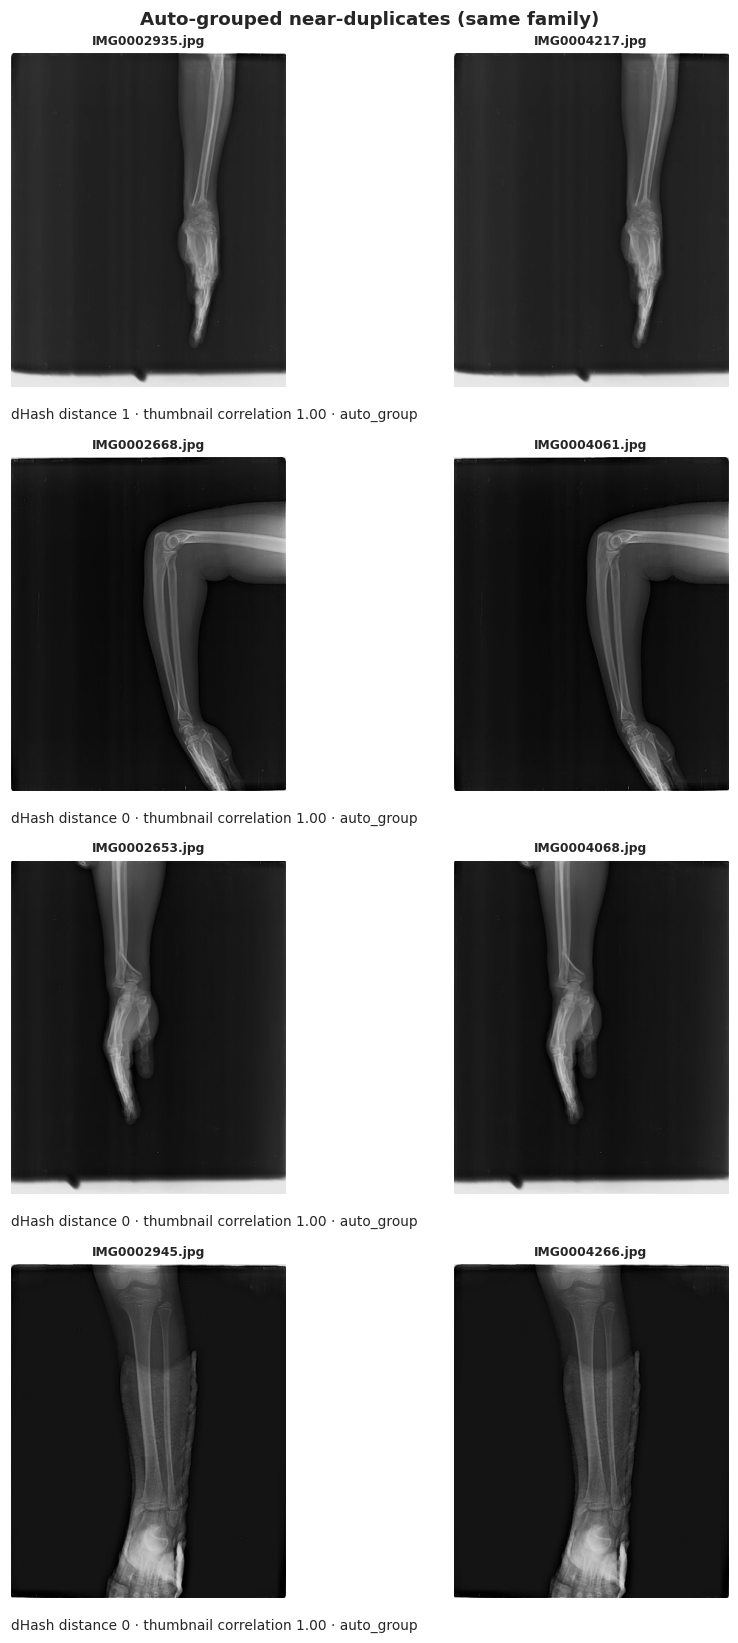

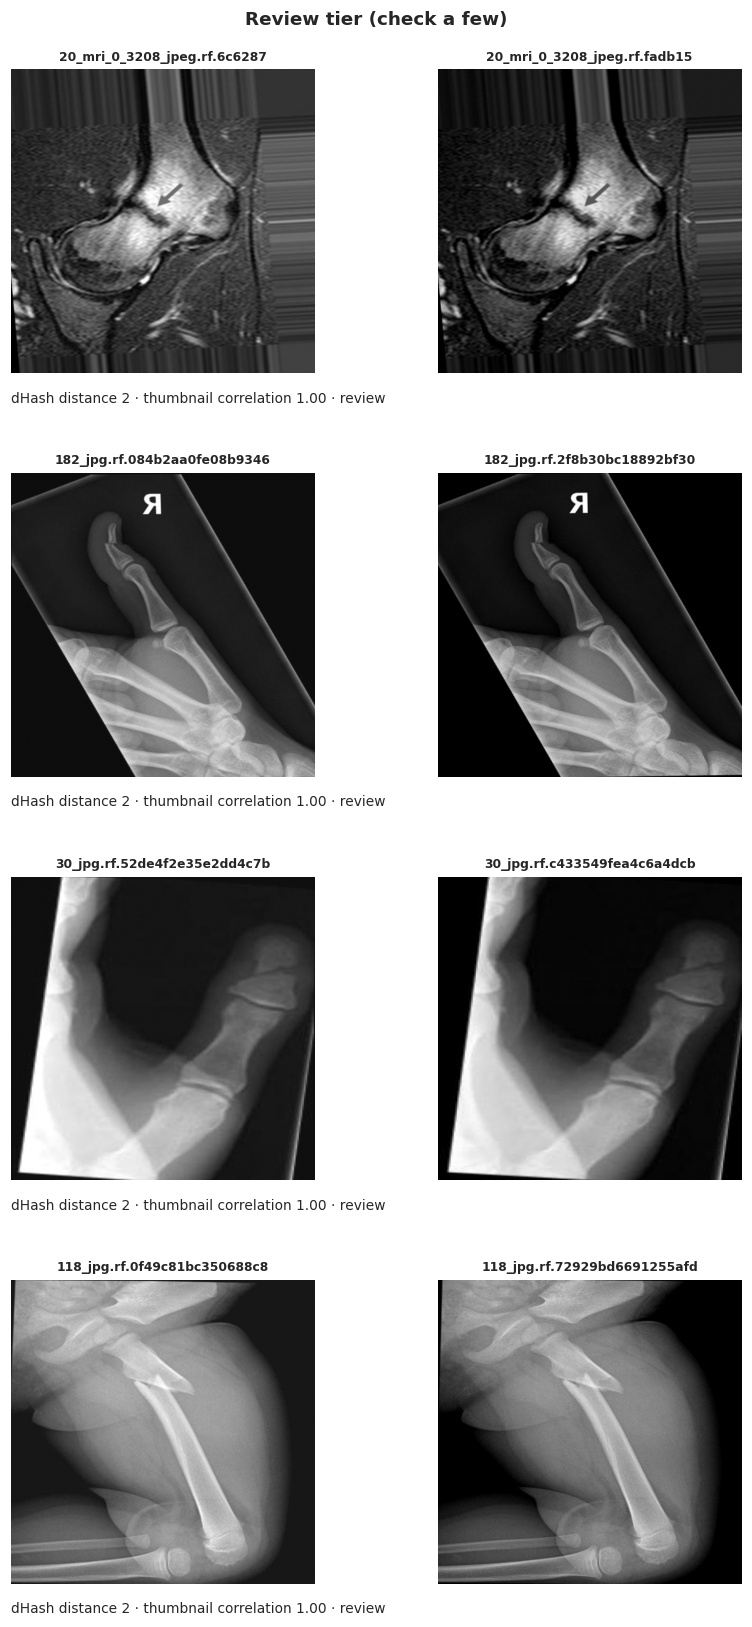

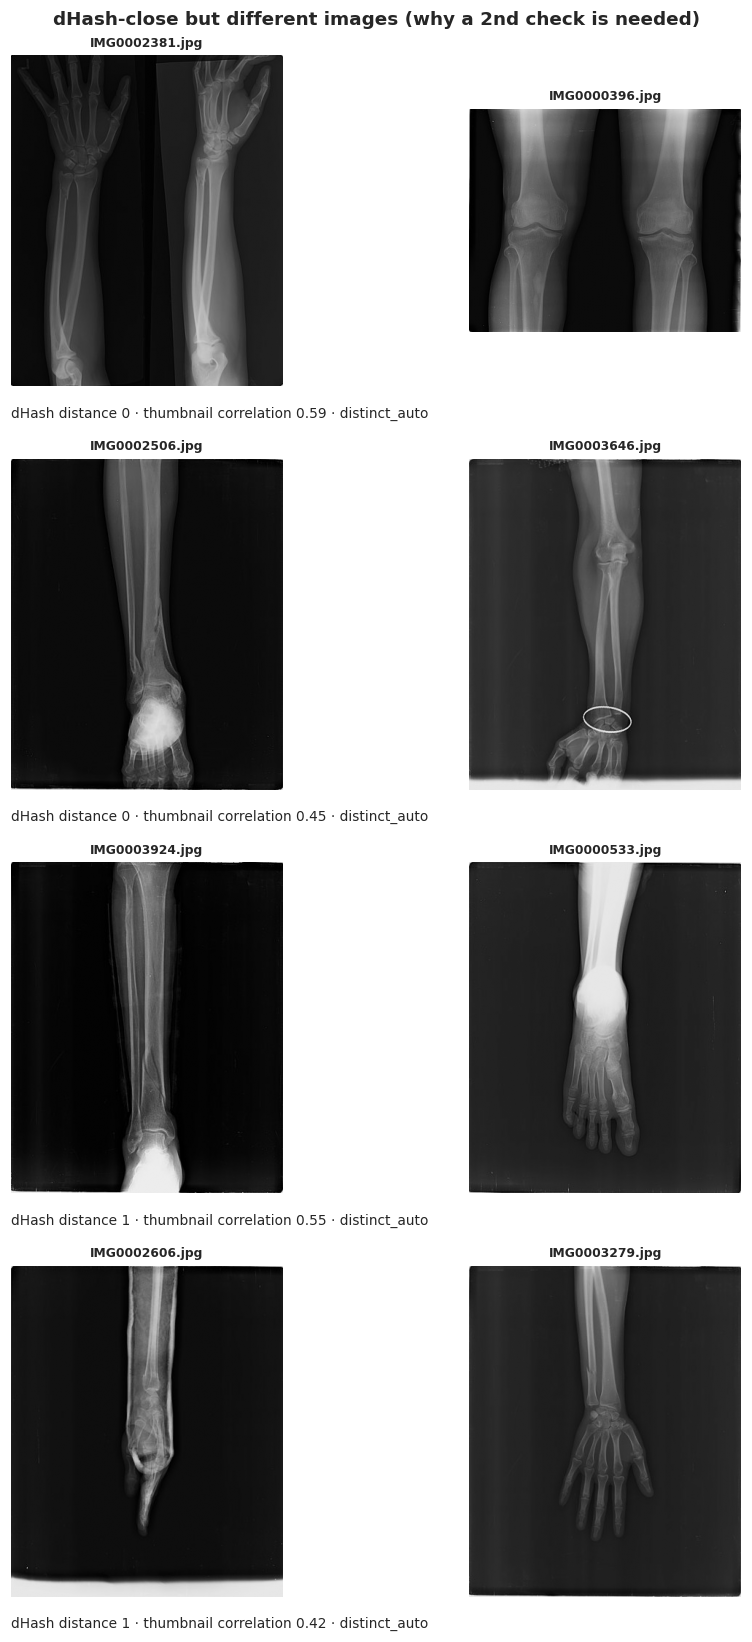

In [8]:
def pair_gallery(pairs, title, name, n=4):
    pairs = pairs.head(n)
    if pairs.empty: return
    fig, axes = plt.subplots(len(pairs), 2, figsize=(7, 3.8 * len(pairs)), squeeze=False)
    for row, (_, r) in zip(axes, pairs.iterrows()):
        for ax, p in zip(row, [r.path_a, r.path_b]):
            with Image.open(p) as im: g = safe_rgb(im).convert('L'); g.thumbnail((480, 480))
            ax.imshow(g, cmap='gray', vmin=0, vmax=255); ax.axis('off')
        row[0].set_title(Path(r.path_a).name[:28], fontsize=8); row[1].set_title(Path(r.path_b).name[:28], fontsize=8)
        row[0].text(0.0, -0.06, f'dHash distance {r.dhash_dist} · thumbnail correlation {r["corr"]:.2f} · {r.tier}',
                    transform=row[0].transAxes, fontsize=9, va='top')
    fig.suptitle(title, fontsize=12, fontweight='bold'); finish(fig, name, svg=False)

if DISPLAY_GALLERIES:
    pair_gallery(near[near.tier == 'auto_group'].sort_values('corr', ascending=False), 'Auto-grouped near-duplicates (same family)', '07_pairs_auto')
    pair_gallery(near[near.tier == 'review'].sort_values('corr', ascending=False), 'Review tier (check a few)', '07_pairs_review')
    pair_gallery(near[near.tier == 'distinct_auto'].sort_values('dhash_dist'), 'dHash-close but different images (why a 2nd check is needed)', '07_pairs_rejected')

## 7 · Galleries and dataset shift
Use galleries to spot padding, text markers, implants, multi-view composites and augmentation artifacts. The HBFMID family gallery shows what one original looks like after Roboflow augmentation. Appearance statistics describe the datasets; they do not prove clinical generalisation.

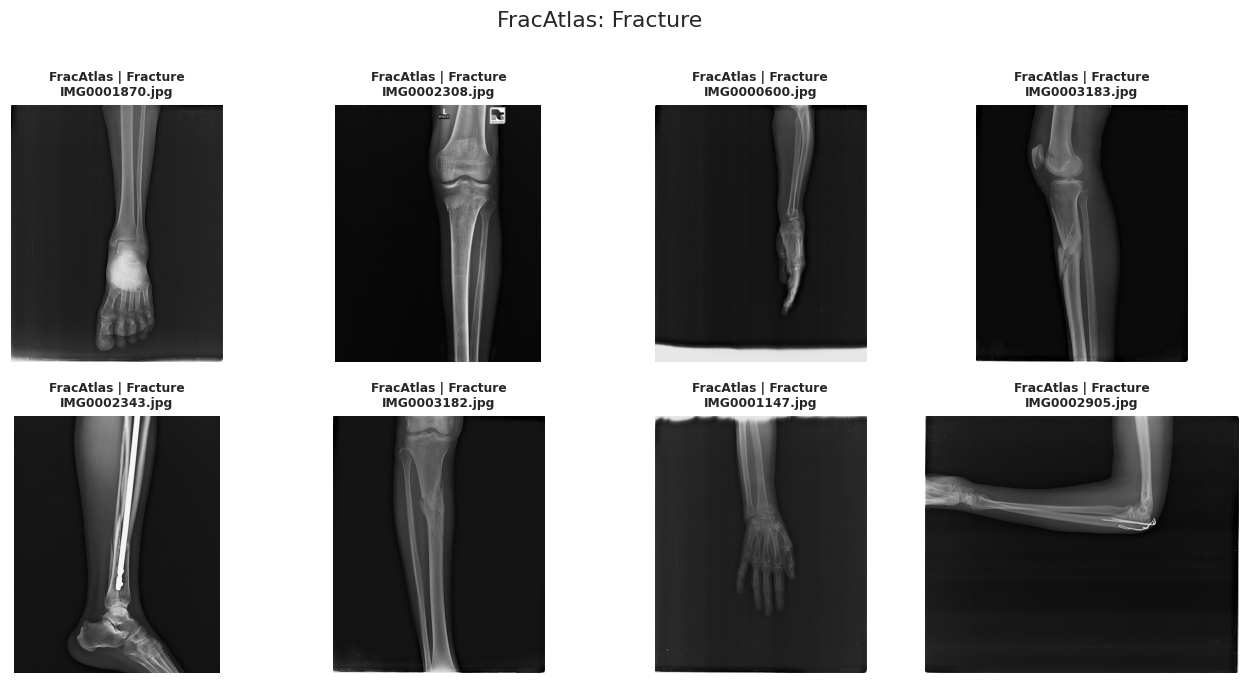

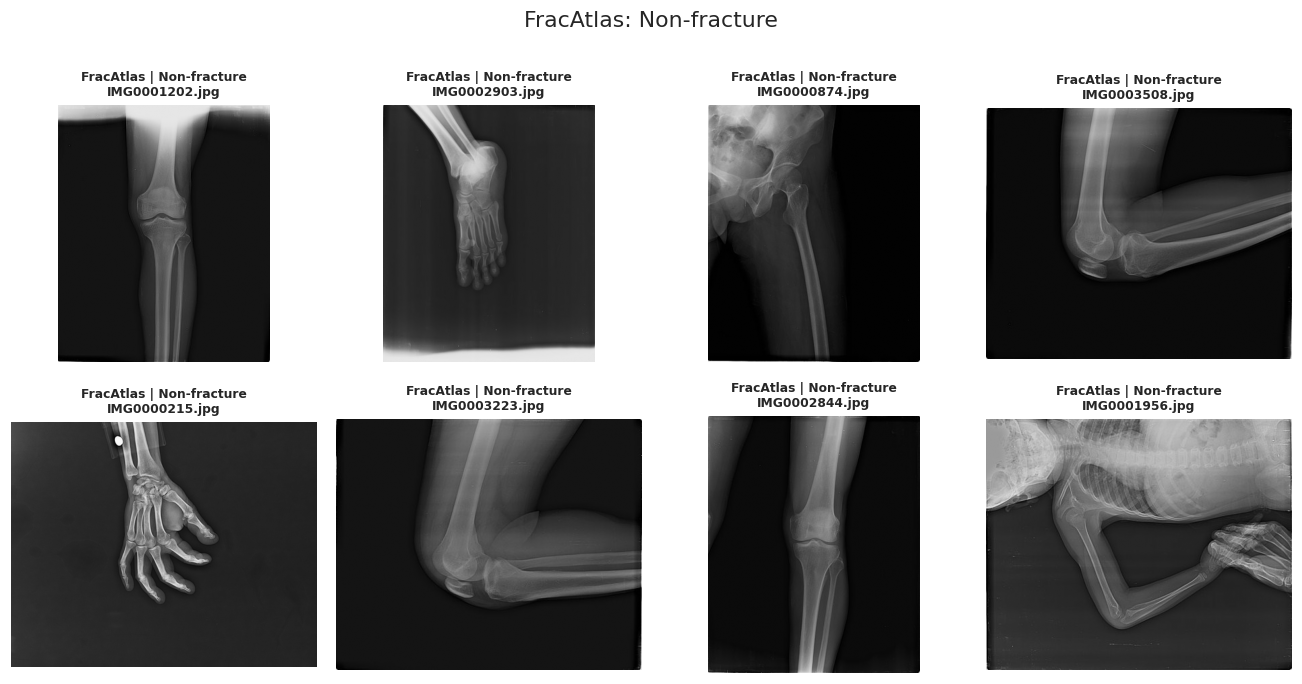

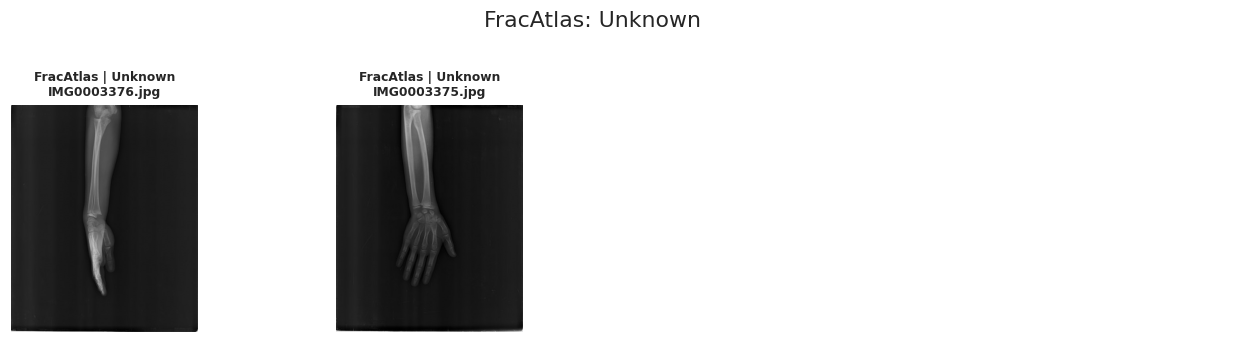

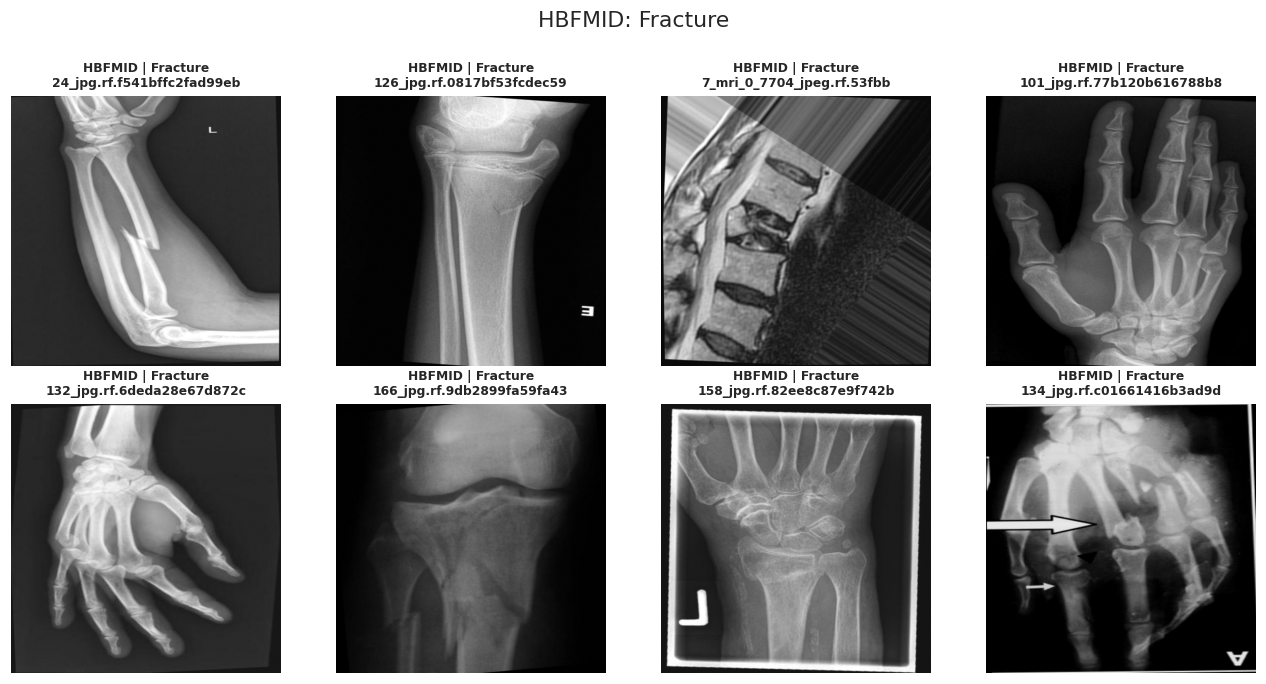

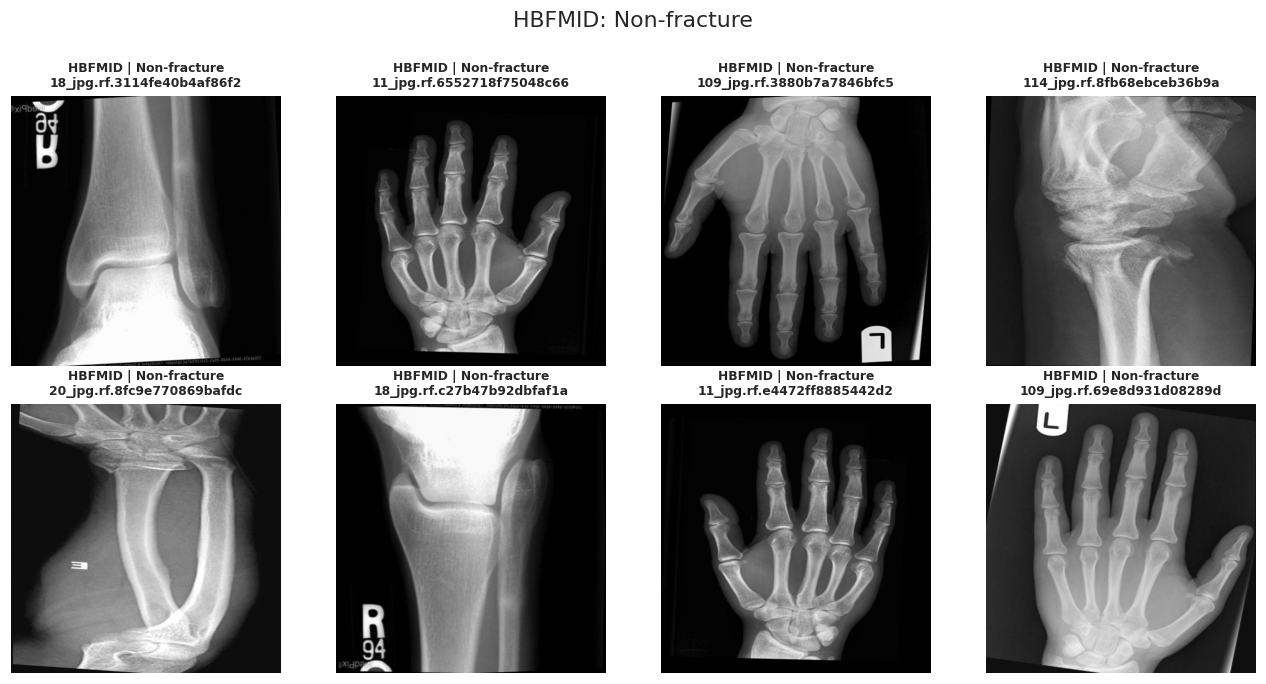

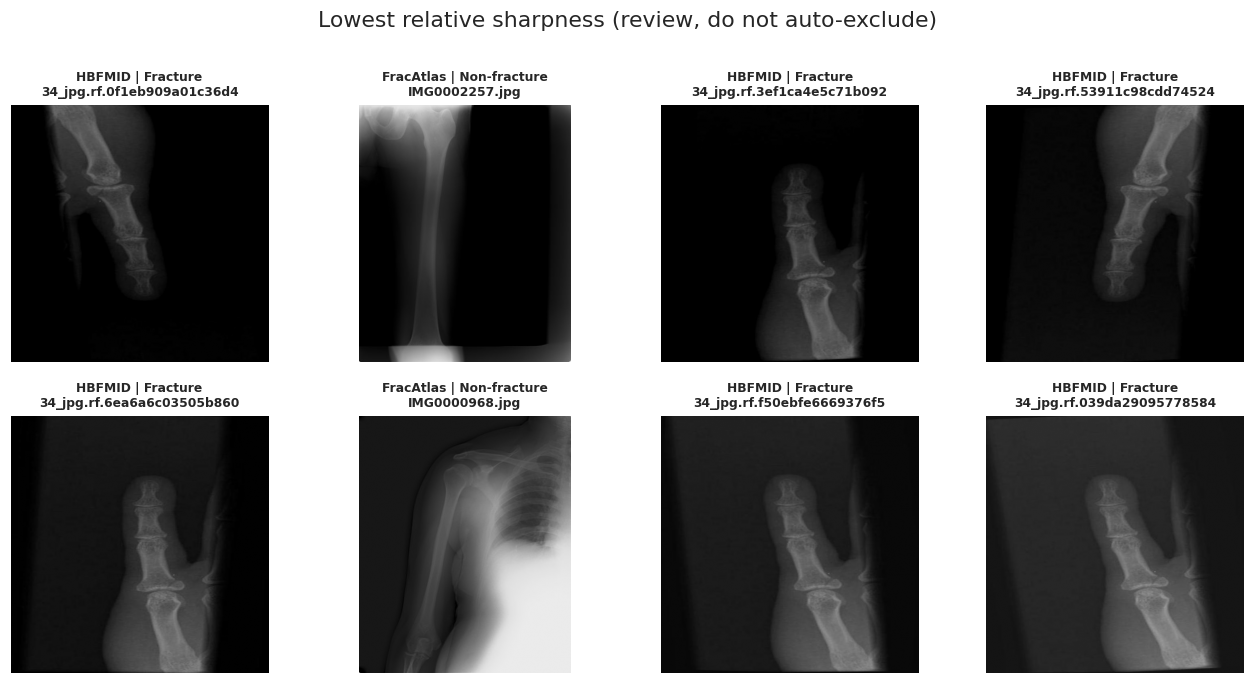

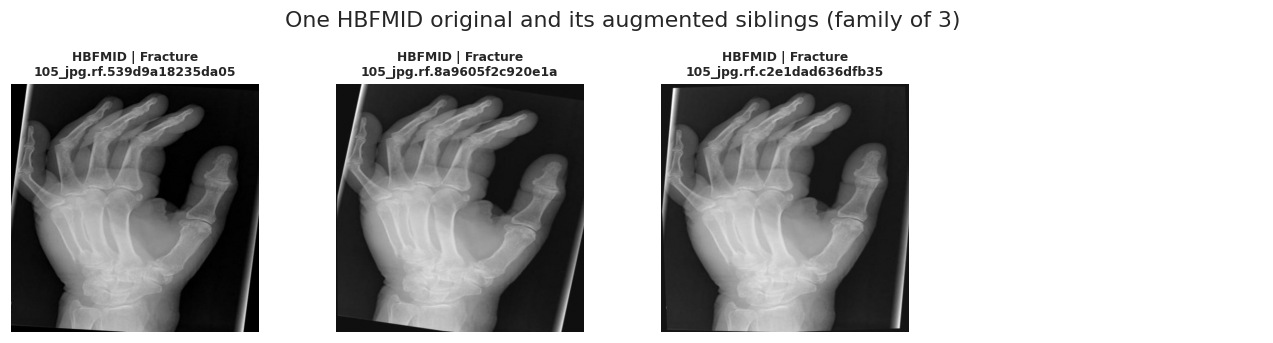

,aspect,brightness,contrast,entropy,blur_score,dark_fraction,bright_fraction,border_mean
dataset,,,,,,,,
FracAtlas,0.822,0.186,0.160,3.645,0.003,0.004,0.0,0.307
HBFMID,1.000,0.247,0.236,4.531,0.004,0.137,0.0,0.081


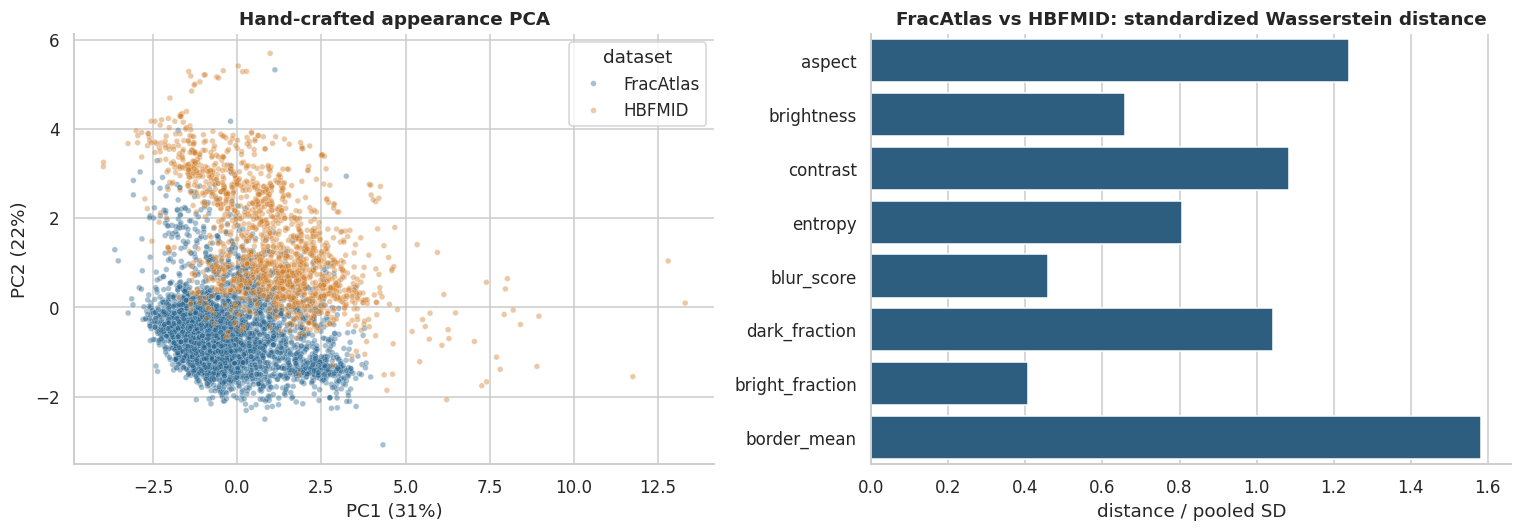

In [9]:
def gallery(rows, title, name, cols=4):
    rows = rows.head(12)
    if rows.empty: return
    nr = int(np.ceil(len(rows) / cols))
    fig, axes = plt.subplots(nr, cols, figsize=(cols * 3, 3.1 * nr), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        with Image.open(r.path) as im: g = safe_rgb(im).convert('L'); g.thumbnail((512, 512))
        ax.imshow(g, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'{r.dataset} | {r["class"]}\n{Path(r.path).name[:26]}', fontsize=8)
    fig.suptitle(title, y=1.0); finish(fig, name, svg=False)

if DISPLAY_GALLERIES:
    for (ds, cl), sub in good.groupby(['dataset', 'class']):
        gallery(sub.sample(min(8, len(sub)), random_state=SEED), f'{ds}: {cl}', f'08_gallery_{ds}_{cl}')
    gallery(good.nsmallest(8, 'blur_score'), 'Lowest relative sharpness (review, do not auto-exclude)', '09_low_sharpness')
    fam = good[(good.dataset == 'HBFMID') & good.source_id.notna()]
    sizes = fam.groupby('source_id').size(); pick = sizes[sizes == 3].index
    if len(pick): gallery(fam[fam.source_id == pick[0]], 'One HBFMID original and its augmented siblings (family of 3)', '10_hbfmid_family')

FEATURES = ['aspect', 'brightness', 'contrast', 'entropy', 'blur_score', 'dark_fraction', 'bright_fraction', 'border_mean']
display(good.groupby('dataset')[FEATURES].median().round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if len(good) >= 3 and good.dataset.nunique() > 1:
    zc = PCA(2, random_state=SEED).fit(StandardScaler().fit_transform(good[FEATURES].fillna(0)))
    emb = zc.transform(StandardScaler().fit_transform(good[FEATURES].fillna(0)))
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=good.dataset, palette=COLORS, alpha=.4, s=14, ax=axes[0])
    axes[0].set(title='Hand-crafted appearance PCA', xlabel=f'PC1 ({zc.explained_variance_ratio_[0]:.0%})', ylabel=f'PC2 ({zc.explained_variance_ratio_[1]:.0%})')
    a_n, b_n = good.dataset.unique()[:2]; sh = []
    for c in FEATURES:
        a = good.loc[good.dataset == a_n, c].dropna(); b = good.loc[good.dataset == b_n, c].dropna(); sd = good[c].std()
        sh.append({'feature': c, 'shift': wasserstein_distance(a, b) / sd if sd > 0 else np.nan})
    sh = pd.DataFrame(sh); export(sh, 'appearance_shift')
    sns.barplot(data=sh, x='shift', y='feature', color=COLORS['FracAtlas'], ax=axes[1])
    axes[1].set(title=f'{a_n} vs {b_n}: standardized Wasserstein distance', xlabel='distance / pooled SD', ylabel='')
finish(fig, '11_dataset_shift')

## 8 · Eligibility waterfall
Each step shows how many images survive and why the rest are dropped.

* **Primary (training/validation/test)** = FracAtlas: labeled, X-ray, original, single-frame, not high-bit-depth, not in a label-conflict, exact copies removed.
* **External** = HBFMID: labeled X-ray **originals** (valid/test folders, never the augmented train folder), minus any family that also appears in FracAtlas. If HBFMID has no labels, it is parked as *pending* instead of being guessed.

In [10]:
def waterfall(frame, steps):
    cur = frame; rows = [('readable', len(cur), int(cur.label.fillna(0).sum()))]
    for text, fn in steps:
        cur = cur.loc[fn(cur).fillna(False).astype(bool)]
        rows.append((text, len(cur), int(cur.label.fillna(0).sum())))
    return cur, pd.DataFrame(rows, columns=['step', 'images', 'fractured'])

common = [('single-frame, not high-bit-depth', lambda d: (d.frames == 1) & ~d.high_bit_depth),
          ('not a label-conflict copy', lambda d: ~d.pixel_sha256.isin(conf_ids)),
          ('label agrees with COCO boxes (if available)', lambda d: pd.to_numeric(d.has_box, errors='coerce').isna()
                                                                   | (pd.to_numeric(d.has_box, errors='coerce') == d.label.astype('float')))]
prim_pool, wf_p = waterfall(good[good.dataset == 'FracAtlas'].sort_values('relative_path'),
    [('label known', lambda d: d.label.notna()), ('X-ray', lambda d: d.modality.eq('xray')),
     ('original (not augmented)', lambda d: d.is_augmented.eq(0))] + common)
primary = prim_pool.drop_duplicates('pixel_sha256').copy()
wf_p.loc[len(wf_p)] = ['exact duplicates removed', len(primary), int(primary.label.sum())]
ext_pool, wf_e = waterfall(good[good.dataset == 'HBFMID'],
    [('label known', lambda d: d.label.notna()), ('X-ray', lambda d: d.modality.eq('xray')),
     ('original (valid/test, not augmented)', lambda d: d.is_augmented.eq(0))] + common)
external = ext_pool.drop_duplicates('pixel_sha256').copy()
overlap = external.group_id.isin(primary.group_id)
export(external[overlap], 'external_overlap_exclusions')
external = external[~overlap].copy()
wf_e.loc[len(wf_e)] = ['no overlap with FracAtlas families', len(external), int(external.label.sum())]
display(wf_p.assign(set='FracAtlas (primary)')); display(wf_e.assign(set='HBFMID (external)'))
export(pd.concat([wf_p.assign(set='primary'), wf_e.assign(set='external')]), 'eligibility_waterfall')
export(good[~good.path.isin(set(primary.path) | set(external.path))][['dataset', 'relative_path', 'label', 'modality', 'is_augmented', 'group_id']], 'excluded_or_unresolved')
n_neg_ext = int((external.label == 0).sum()) if len(external) else 0
if len(external) and n_neg_ext < 30:
    note('warn', f'External set has only {n_neg_ext} negatives (HBFMID "Healthy", mostly augmented copies of few originals): '
                 'specificity/AUROC there are unreliable; report sensitivity with a Wilson interval.')
if primary.empty: note('error', 'No eligible FracAtlas images; fix labels/metadata (sections 2-3) before continuing.')
if external.empty:
    why = 'HBFMID has no labels' if good[good.dataset == 'HBFMID'].label.isna().all() else 'no labeled X-ray originals remain'
    note('warn', f'External set is empty: {why}. HBFMID stays pending until labels/originals are confirmed.')
elif external.label.nunique() < 2:
    note('warn', f'External set is single-class (all label={int(external.label.iloc[0])}): report sensitivity only; no AUROC/specificity.')
summary.update(primary_images=len(primary), primary_positive=int(primary.label.sum()) if len(primary) else 0,
               external_images=len(external), external_single_class=bool(len(external) and external.label.nunique() < 2))

,step,images,fractured,set
0,readable,4085,719,FracAtlas (primary)
1,label known,4083,719,FracAtlas (primary)
2,X-ray,4083,719,FracAtlas (primary)
3,original (not augmented),4083,719,FracAtlas (primary)
4,"single-frame, not high-bit-depth",4083,719,FracAtlas (primary)
5,not a label-conflict copy,4076,716,FracAtlas (primary)
6,label agrees with COCO boxes (if available),4076,716,FracAtlas (primary)
7,exact duplicates removed,3996,701,FracAtlas (primary)


,step,images,fractured,set
0,readable,1539,1472,HBFMID (external)
1,label known,1539,1472,HBFMID (external)
2,X-ray,1337,1270,HBFMID (external)
3,"original (valid/test, not augmented)",164,154,HBFMID (external)
4,"single-frame, not high-bit-depth",164,154,HBFMID (external)
5,not a label-conflict copy,164,154,HBFMID (external)
6,label agrees with COCO boxes (if available),164,154,HBFMID (external)
7,no overlap with FracAtlas families,161,151,HBFMID (external)


[WARN] External set has only 10 negatives (HBFMID "Healthy", mostly augmented copies of few originals): specificity/AUROC there are unreliable; report sensitivity with a Wilson interval.


## 9 · Grouped split, label budgets and training statistics
* Stratified **group** 10-fold → **70 % train / 10 % validation / 20 % test** by image count; whole families stay together. This replaces any published split and must not be reported as the official benchmark.
* FracAtlas has no patient IDs, so the split is family-level, not patient-level. 
* Nested low-label budgets (1/5/10/25/100 %) are drawn **from training families only**, per class, with 3 seeds.
* Class weights and normalisation statistics come from the **training split only**.

,images,fractured,families,prevalence,image_share
proposed_split,,,,,
test,771,122,711,0.158,0.193
train,2821,507,2603,0.18,0.706
validation,404,72,374,0.178,0.101


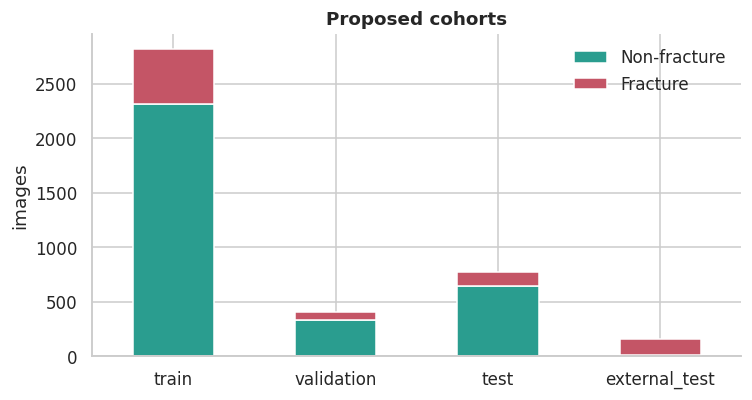

[INFO] label budgets [0.01] contain <10 fractured images: results at those sizes are very unstable.


,seed,fraction,families,images,image_share,fractured,non_fractured
0,42,0.01,27,29,0.010,5,24
1,42,0.05,131,135,0.048,24,111
2,42,0.10,261,268,0.095,49,219
3,42,0.25,652,728,0.258,135,593
4,42,1.00,2603,2821,1.000,507,2314


{
  "train_images": 2821,
  "class_weights": {
    "non_fracture": 0.6096,
    "fracture": 2.7821,
    "pos_weight_for_BCEWithLogits": 4.5641
  },
  "grayscale_mean": 0.2031,
  "grayscale_std": 0.1909,
  "note": "thumbnail estimate; recompute at final input size"
}


In [11]:
READY = False
if not MAKE_SPLITS: print('MAKE_SPLITS is False; skipped.')
elif primary.empty or truncated: note('error', 'Split skipped (no eligible images or incomplete near-duplicate search).')
elif primary.patient_id.isna().any() and not ALLOW_IMAGE_LEVEL_SPLIT: note('error', 'Patient IDs missing and ALLOW_IMAGE_LEVEL_SPLIT=False.')
elif primary.label.nunique() < 2 or primary.groupby('label').group_id.nunique().min() < 10:
    note('error', 'Need both classes with >=10 families each for the 10-fold design.')
else:
    primary = primary.reset_index(drop=True)
    folds = np.full(len(primary), -1)
    cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
    for k, (_, idx) in enumerate(cv.split(primary, primary.label.astype(int), primary.group_id)): folds[idx] = k
    primary['proposed_split'] = np.where(folds < 2, 'test', np.where(folds == 2, 'validation', 'train'))
    # hard guarantees
    assert primary.groupby('group_id').proposed_split.nunique().max() == 1, 'a family straddles splits'
    assert primary.groupby('pixel_sha256').proposed_split.nunique().max() == 1, 'identical pixels in two splits'
    for s, g in primary.groupby('proposed_split'): assert g.label.nunique() == 2, f'{s} has one class'
    primary['patient_level'] = primary.patient_id.notna()
    external['proposed_split'] = 'external_test'
    manifest = pd.concat([primary, external], ignore_index=True)
    export(manifest.drop(columns=['tiny'], errors='ignore'), 'split_manifest')
    tab = primary.groupby('proposed_split').agg(images=('path', 'size'), fractured=('label', 'sum'), families=('group_id', 'nunique'))
    tab['prevalence'] = (tab.fractured / tab.images).round(3); tab['image_share'] = (tab.images / len(primary)).round(3)
    display(tab); export(tab.reset_index(), 'split_summary')
    fig, ax = plt.subplots(figsize=(7, 3.8))
    (pd.crosstab(manifest.proposed_split, manifest.label).rename(columns={0: 'Non-fracture', 1: 'Fracture'})
       .reindex(['train', 'validation', 'test', 'external_test']).dropna(how='all')
       .plot.bar(stacked=True, ax=ax, color=[COLORS['Non-fracture'], COLORS['Fracture']], rot=0))
    ax.set(title='Proposed cohorts', xlabel='', ylabel='images'); ax.legend(frameon=False); finish(fig, '12_split_counts')

    train = primary[primary.proposed_split == 'train']
    export(train[['path', 'group_id']], 'ssl_train_pool')
    gt = train.groupby('group_id').label.max()       # mixed-label family counts as positive
    bud, rows, tiny_budget = [], [], set()
    for seed in BUDGET_SEEDS:
        rng = np.random.default_rng(seed)
        order = {int(l): rng.permutation(gg.index.to_numpy()) for l, gg in gt.groupby(gt)}
        prev = set()
        for f in BUDGET_FRACTIONS:
            sel = set()
            for l, ids in order.items(): sel.update(ids[:max(1, int(np.ceil(len(ids) * f)))])
            assert prev <= sel; prev = sel
            sub = train[train.group_id.isin(sel)]
            if sub.label.nunique() < 2: note('warn', f'budget {f:.0%} seed {seed} has one class')
            if sub.label.sum() < 10: tiny_budget.add(f)
            rows.append(sub[['path', 'group_id', 'label']].assign(seed=seed, fraction=f))
            bud.append(dict(seed=seed, fraction=f, families=len(sel), images=len(sub), image_share=round(len(sub) / len(train), 3),
                            fractured=int(sub.label.sum()), non_fractured=int((sub.label == 0).sum())))
    if tiny_budget: note('info', f'label budgets {sorted(tiny_budget)} contain <10 fractured images: results at those sizes are very unstable.')
    export(pd.concat(rows), 'label_budgets'); bud = pd.DataFrame(bud); export(bud, 'label_budget_summary')
    display(bud[bud.seed == BUDGET_SEEDS[0]])

    n1, n0 = int(train.label.sum()), int((train.label == 0).sum())
    class_weights = {'non_fracture': round(len(train) / (2 * n0), 4), 'fracture': round(len(train) / (2 * n1), 4),
                     'pos_weight_for_BCEWithLogits': round(n0 / n1, 4)}
    npx = train.thumbnail_pixels.sum(); mean = train.intensity_sum.sum() / npx
    std = float(np.sqrt(max(0., train.intensity_sq_sum.sum() / npx - mean ** 2)))
    stats = {'train_images': len(train), 'class_weights': class_weights, 'grayscale_mean': round(float(mean), 4),
             'grayscale_std': round(std, 4), 'note': 'thumbnail estimate; recompute at final input size'}
    (OUT / 'train_statistics.json').write_text(json.dumps(stats, indent=2)); print(json.dumps(stats, indent=2))
    summary.update(splits_generated=True, patient_level_split=bool(primary.patient_id.notna().all()), train_stats=stats)
    READY = True
_ = summary.setdefault('splits_generated', False)

## 10 · Augmentation policy (training only)
**Decision:** yes for FracAtlas training images, applied *on the fly after the split*; never to validation/test; never saved as extra files. **No** extra augmentation for HBFMID: its training folder is already augmented (rotation wedges and edge-fill streaks are visible in the family gallery).

Imbalance is handled with the class weights above, not by duplicating images. The preview below uses a mild, anatomy-preserving policy whose fill value is the image-border median, so it does not create the black wedges that HBFMID's pre-augmentation contains.

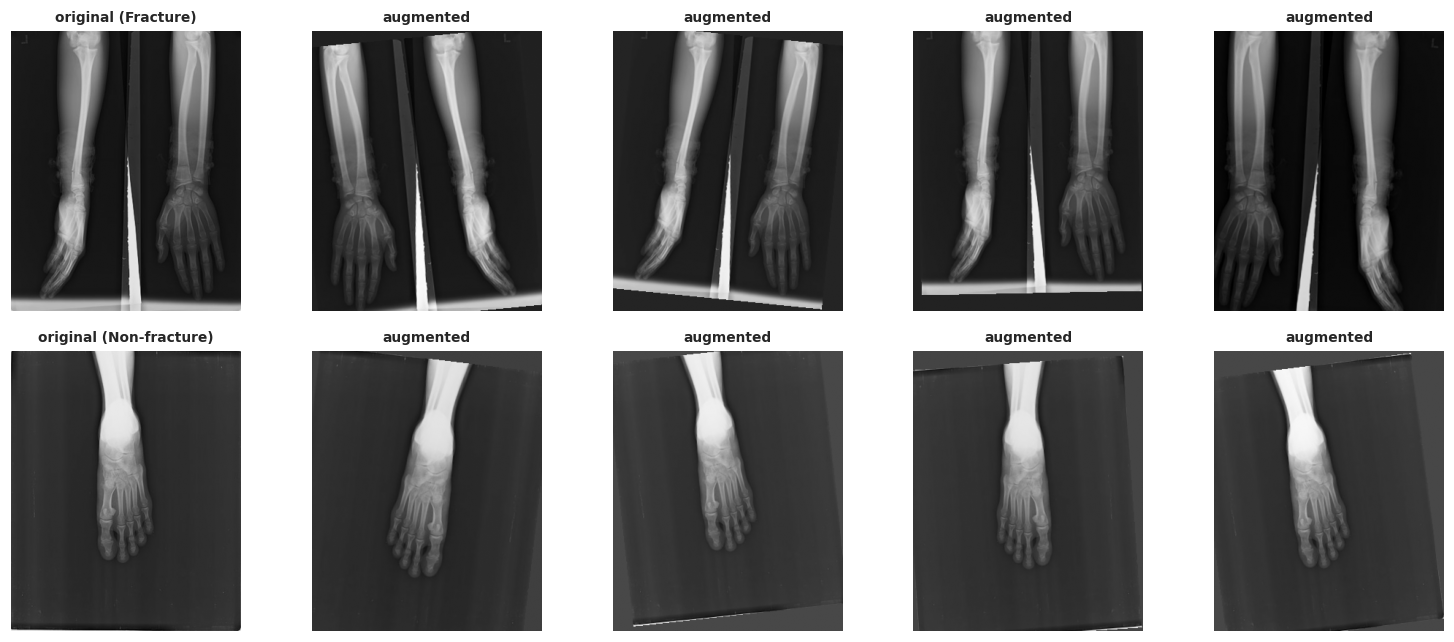

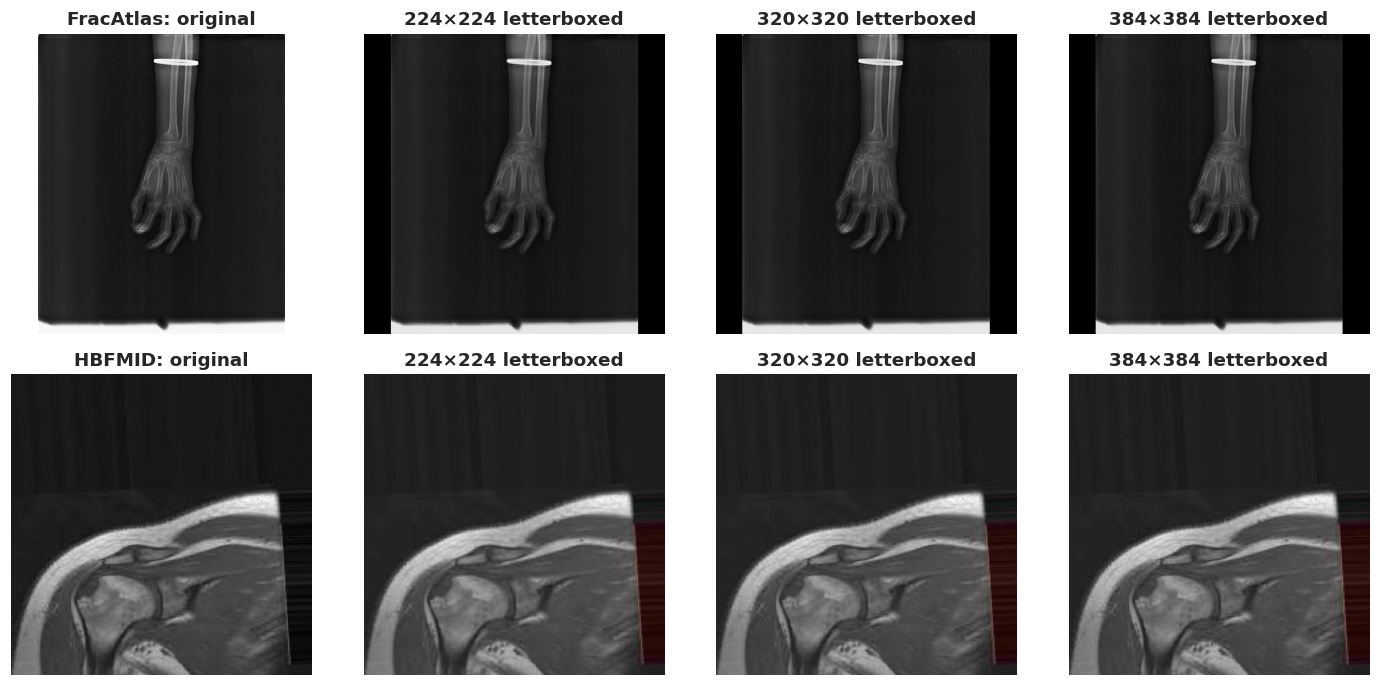

In [12]:
POLICY = {'apply_to': 'train split only, on the fly', 'rotation_deg': 10, 'scale': [0.92, 1.08], 'translate_frac': 0.05,
          'hflip_p': 0.5, 'brightness_shift': 0.05, 'contrast_range': [0.9, 1.1],
          'never': ['vertical flip', 'strong crop / random-erasing over the bone', 'elastic warps', 'any change to val/test'],
          'fill': 'border median (no black wedges)'}
(OUT / 'augmentation_policy.json').write_text(json.dumps(POLICY, indent=2))

def mild_aug(g, rng):
    w, h = g.size; cx, cy = w / 2, h / 2
    th = np.deg2rad(rng.uniform(-POLICY['rotation_deg'], POLICY['rotation_deg'])); sc = rng.uniform(*POLICY['scale'])
    tx, ty = rng.uniform(-1, 1, 2) * POLICY['translate_frac'] * np.array([w, h]); c, s = np.cos(th), np.sin(th)
    arr = np.asarray(g); border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
    out = g.transform((w, h), Image.AFFINE, (c / sc, s / sc, cx - (c * cx + s * cy) / sc - tx,
                                              -s / sc, c / sc, cy - (-s * cx + c * cy) / sc - ty),
                      resample=Image.Resampling.BILINEAR, fillcolor=int(np.median(border)))
    if rng.random() < POLICY['hflip_p']: out = ImageOps.mirror(out)
    a = np.asarray(out, dtype=np.float32); m = a.mean()
    a = (a - m) * rng.uniform(*POLICY['contrast_range']) + m + rng.uniform(-1, 1) * POLICY['brightness_shift'] * 255
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))

pool = train if READY else good[good.dataset == 'FracAtlas']
if DISPLAY_GALLERIES and len(pool):
    rng = np.random.default_rng(SEED)
    picks = [pool[pool.label == 1].sample(1, random_state=SEED).iloc[0]] if (pool.label == 1).any() else []
    picks += [pool[pool.label == 0].sample(1, random_state=SEED).iloc[0]] if (pool.label == 0).any() else []
    fig, axes = plt.subplots(len(picks), 5, figsize=(14, 3 * len(picks)), squeeze=False)
    for row, r in zip(axes, picks):
        with Image.open(r.path) as im: g = safe_rgb(im).convert('L'); g.thumbnail((384, 384))
        row[0].imshow(g, cmap='gray', vmin=0, vmax=255); row[0].set_title(f'original ({r["class"]})', fontsize=9)
        for ax in row[1:]: ax.imshow(mild_aug(g, rng), cmap='gray', vmin=0, vmax=255); ax.set_title('augmented', fontsize=9)
        for ax in row: ax.axis('off')
    finish(fig, '13_augmentation_preview', svg=False)

def letterbox(im, size):
    im = safe_rgb(im); r = ImageOps.contain(im, (size, size), Image.Resampling.LANCZOS)
    c = Image.new('RGB', (size, size)); c.paste(r, ((size - r.width) // 2, (size - r.height) // 2)); return c
if DISPLAY_GALLERIES:
    ex = good.groupby('dataset', group_keys=False).sample(1, random_state=SEED)
    fig, axes = plt.subplots(len(ex), 4, figsize=(13, 3.2 * len(ex)), squeeze=False)
    for row, (_, r) in zip(axes, ex.iterrows()):
        with Image.open(r.path) as im:
            row[0].imshow(safe_rgb(im).convert('L'), cmap='gray'); row[0].set_title(f'{r.dataset}: original')
            for ax, s in zip(row[1:], [224, 320, 384]): ax.imshow(letterbox(im, s)); ax.set_title(f'{s}×{s} letterboxed')
        for ax in row: ax.axis('off')
    finish(fig, '14_input_resolution_preview', svg=False)

## 11 · Summary, findings and exports

,dataset,readable,labeled,xray,originals,augmented,unique_pixels,eligible
0,FracAtlas,4085,4083,4085,4085,0,3999,3996
1,HBFMID,1539,1539,1337,192,1347,1539,161


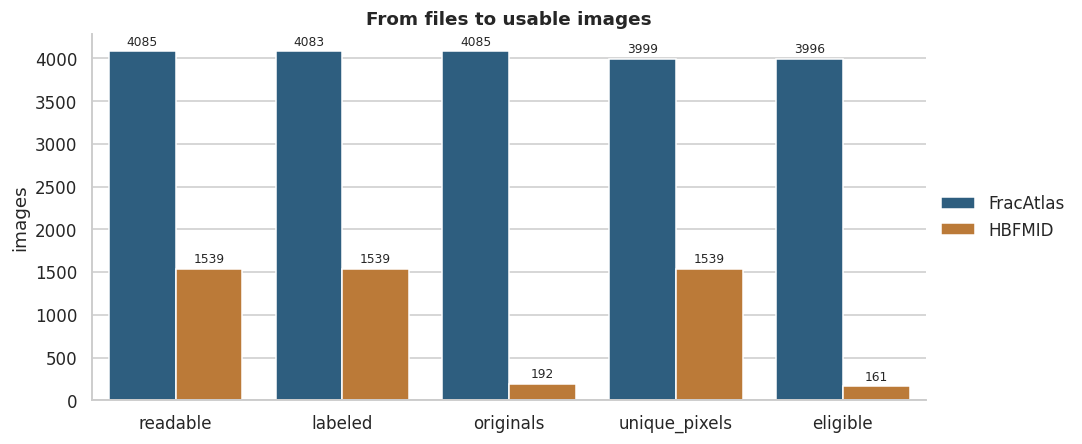


===== FINDINGS =====
[WARN ] FracAtlas: 4 files share a filename across folders (duplicate_filenames.csv). Each is labelled only if its folder agrees with the CSV; otherwise the label stays unknown and the image is excluded.
[WARN ] FracAtlas: 2 images where folder label and CSV label disagree (label_source_conflicts.csv); left unlabeled and excluded.
[WARN ] 7 images share pixels with images of the OPPOSITE label (label noise); they are removed from the cohort.
[WARN ] 3 families contain images from BOTH datasets (external-set overlap; removed from the external set later).
[WARN ] 20 families span more than one published split (publisher splits leak; this notebook re-splits).
[WARN ] External set has only 10 negatives (HBFMID "Healthy", mostly augmented copies of few originals): specificity/AUROC there are unreliable; report sensitivity with a Wilson interval.
[INFO ] HBFMID: 1,539/1,539 images matched to a YOLO label file.
[INFO ] FracAtlas: prevalence 17.6%; use class weights / bal

In [13]:
dash = good.groupby('dataset').agg(readable=('path', 'size'), labeled=('label', 'count'),
        xray=('modality', lambda s: int(s.eq('xray').sum())), originals=('is_augmented', lambda s: int(s.eq(0).sum())),
        augmented=('is_augmented', lambda s: int(s.eq(1).sum())), unique_pixels=('pixel_sha256', 'nunique')).reset_index()
dash['eligible'] = dash.dataset.map({'FracAtlas': len(primary), 'HBFMID': len(external)})
export(dash, 'executive_summary'); display(dash)
long = dash.melt(id_vars='dataset', value_vars=['readable', 'labeled', 'originals', 'unique_pixels', 'eligible'], var_name='stage', value_name='images')
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.barplot(data=long, x='stage', y='images', hue='dataset', palette=COLORS, ax=ax)
for c in ax.containers: ax.bar_label(c, fmt='%.0f', fontsize=8, padding=2)
ax.set(title='From files to usable images', xlabel='', ylabel='images'); sns.move_legend(ax, 'center left', bbox_to_anchor=(1, .5), frameon=False, title=''); finish(fig, '15_executive_summary')

known_aug = int(good.is_augmented.notna().sum())
summary['augmentation_decision'] = ('FracAtlas: mild on-the-fly training-only augmentation + class weights; '
                                    'HBFMID: already augmented, add none, evaluate on originals only.')
(OUT / 'audit_summary.json').write_text(json.dumps(summary, indent=2, default=str))

print('\n===== FINDINGS =====')
order = {'error': 0, 'warn': 1, 'info': 2}
for lvl, msg in sorted(FINDINGS, key=lambda t: order[t[0]]): print(f'[{lvl.upper():5}] {msg}')
pd.DataFrame(FINDINGS, columns=['level', 'message']).to_csv(OUT / 'findings.csv', index=False)
zip_path = shutil.make_archive(str(OUT.parent / 'fracture_eda_outputs'), 'zip', OUT)
print('\nOutputs:', OUT, '\nZip   :', zip_path)

# Part B · Fixing class imbalance: weighted loss, focal loss and minority-class augmentation
Uses `split_manifest.csv` from the EDA part (family-grouped train / validation / test, plus the external set). FracAtlas is ~18 % fracture, so a model can score ~82 % accuracy by always answering "no fracture". This part compares ways to fix that **under identical conditions**.

**Fair-comparison rules (all enforced in code)**
* Same split, backbone, optimiser, schedule, epochs and seeds for every experiment; only the imbalance strategy changes.
* Augmentation touches **training images only**; validation / test / external are never augmented.
* Model selection (best epoch, decision threshold, best experiment) uses **validation only**. The test set is read once, at the end.
* Imbalance-aware metrics: AUPRC and sensitivity/specificity, not accuracy. Confidence intervals come from a **cluster bootstrap over image families**, with paired differences against the baseline.

| # | Experiment | Loss | Augmentation | Sampling |
|---|---|---|---|---|
| 1 | `bce` (baseline) | plain BCE | none | natural |
| 2 | `wbce` | BCE with `pos_weight = n_neg/n_pos` | none | natural |
| 3 | `focal` | focal loss (γ=2, α=1−prevalence) | none | natural |
| 4 | `bce_minaug_bal` | plain BCE | **fracture class only** | fracture images oversampled to 50 % of each batch |
| 5 | `wbce_minaug` | weighted BCE | fracture class only | natural |
| 6 | `focal_minaug` | focal | fracture class only | natural |
| 7 | `bce_allaug` | plain BCE | both classes (control) | natural |

Experiment 7 shows whether any gain comes from *class-conditional* augmentation or just from augmenting at all. Nothing here is assumed to help: read the paired-difference table before drawing conclusions.

## 12 · Setup
Set `FRACTURE_QUICK=1` only for a smoke test (tiny CNN, 64 px, 2 epochs). For real results use a **GPU** (Kaggle: *Settings → Accelerator*). Pretrained ImageNet weights need internet; with internet off the notebook falls back to random initialisation and says so.

In [14]:
import os, json, time, math, copy, random, shutil, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageFile
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             brier_score_loss, confusion_matrix)
warnings.filterwarnings('ignore', category=FutureWarning)
try:
    from IPython.display import display
except ImportError:
    display = print

# ------------------------------- SETTINGS -------------------------------
QUICK = os.environ.get('FRACTURE_QUICK') == '1'
EDA_DIR  = Path(os.environ.get('FRACTURE_OUT', '/kaggle/working/fracture_eda'))
MANIFEST = Path(os.environ.get('SPLIT_MANIFEST', EDA_DIR / 'split_manifest.csv'))
XOUT = Path(os.environ.get('EXPERIMENT_OUT', EDA_DIR.parent / 'fracture_experiments'))

SEEDS = [42]                  # use [42, 123, 2026] for the final report (mean ± SD, ~3x time)
BACKBONE = 'tiny' if QUICK else 'resnet18'   # 'resnet18' | 'resnet34' | 'efficientnet_b0' | 'tiny'
PRETRAINED = True
IMG_SIZE = 64 if QUICK else 224
EPOCHS   = 2 if QUICK else 12
PATIENCE = 4                  # early stopping on validation AUPRC
BATCH, LR, WD = 32, 3e-4, 1e-4
NUM_WORKERS = 0 if QUICK else 2
N_BOOT = 200 if QUICK else 1000
FOCAL_GAMMA = 2.0
MINORITY_STRENGTH = 1.0       # 1.0 = mild policy; try 1.5 for stronger minority augmentation
SENS_TARGET = 0.90            # screening operating point: lowest-cost threshold with >=90% sensitivity
EXPERIMENTS = [
    dict(key='bce',          label='BCE (baseline)',               loss='bce',  aug='none',     sampler='natural'),
    dict(key='wbce',         label='Weighted BCE',                 loss='wbce', aug='none',     sampler='natural'),
    dict(key='focal',        label='Focal',                        loss='focal', aug='none',    sampler='natural'),
    dict(key='bce_minaug_bal', label='BCE + minority aug + balanced sampler', loss='bce', aug='minority', sampler='balanced'),
    dict(key='wbce_minaug',  label='Weighted BCE + minority aug',  loss='wbce', aug='minority', sampler='natural'),
    dict(key='focal_minaug', label='Focal + minority aug',         loss='focal', aug='minority', sampler='natural'),
    dict(key='bce_allaug',   label='BCE + aug on all (control)',   loss='bce',  aug='all',      sampler='natural'),
]
# ------------------------------------------------------------------------

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
XOUT.mkdir(parents=True, exist_ok=True); (XOUT / 'figures').mkdir(exist_ok=True); (XOUT / 'ckpt').mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 220, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
KEYS = [e['key'] for e in EXPERIMENTS]; LABEL = {e['key']: e['label'] for e in EXPERIMENTS}
PAL = dict(zip(KEYS, sns.color_palette('colorblind', len(KEYS))))

def xfinish(fig, name, svg=True):
    fig.tight_layout(); fig.savefig(XOUT / 'figures' / f'{name}.png', bbox_inches='tight')
    if svg: fig.savefig(XOUT / 'figures' / f'{name}.svg', bbox_inches='tight')
    plt.show(); plt.close(fig)
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(42); torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
print(f'device={DEVICE} | backbone={BACKBONE} | img={IMG_SIZE} | epochs={EPOCHS} | seeds={SEEDS} | quick={QUICK}')
if DEVICE.type == 'cpu' and not QUICK:
    print('WARNING: no GPU detected. 7 experiments x epochs on CPU will be slow; enable a GPU or lower EPOCHS / EXPERIMENTS.')

device=cuda | backbone=resnet18 | img=224 | epochs=12 | seeds=[42] | quick=False


## 13 · Load the split and cache images
Images are decoded once, letterboxed (aspect preserved) to a square and kept in memory as 8-bit grayscale. The code re-checks that **no family appears in two splits** before anything is trained.

In [15]:
if not MANIFEST.exists():
    raise FileNotFoundError(f'{MANIFEST} not found. Run the EDA part first (it writes split_manifest.csv) or set SPLIT_MANIFEST.')
man = pd.read_csv(MANIFEST)
need = {'path', 'label', 'proposed_split', 'group_id', 'dataset'}
if not need <= set(man.columns): raise ValueError(f'manifest is missing columns: {need - set(man.columns)}')
man = man.dropna(subset=['label']).copy(); man['label'] = man.label.astype(int)
parts = {s: man[man.proposed_split == s].reset_index(drop=True) for s in ['train', 'validation', 'test']}
ext = man[man.proposed_split == 'external_test'].reset_index(drop=True)
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert not (set(parts[a].group_id) & set(parts[b].group_id)), f'family leakage between {a} and {b}'
for s, d in parts.items():
    assert d.label.nunique() == 2, f'{s} needs both classes'
tab = pd.DataFrame({s: dict(images=len(d), fractured=int(d.label.sum()), prevalence=round(d.label.mean(), 3),
                            families=d.group_id.nunique()) for s, d in {**parts, 'external': ext}.items() if len(d)}).T
display(tab)
if parts['test'].label.sum() < 50:
    print(f'NOTE: only {int(parts["test"].label.sum())} fractured test images; confidence intervals will be wide.')

ImageFile.LOAD_TRUNCATED_IMAGES = True      # FracAtlas has 59 JPEGs cut off by a few bytes
def load_square(path, size):
    with Image.open(path) as im:
        try: im = ImageOps.exif_transpose(im)
        except Exception: pass
        g = im.convert('L')
    g = ImageOps.contain(g, (size, size), Image.Resampling.LANCZOS)
    canvas = Image.new('L', (size, size), 0); canvas.paste(g, ((size - g.width) // 2, (size - g.height) // 2))
    return torch.from_numpy(np.asarray(canvas).copy())

paths = sorted(set(man.path))
with ThreadPoolExecutor(max_workers=max(1, os.cpu_count() or 2)) as pool:
    IMGS = dict(zip(paths, tqdm(pool.map(lambda p: load_square(p, IMG_SIZE), paths), total=len(paths), desc='Caching images')))
tr_stack = torch.stack([IMGS[p] for p in parts['train'].path]).float() / 255.
MEAN, STD = float(tr_stack.mean()), float(tr_stack.std()); del tr_stack
n_pos, n_neg = int(parts['train'].label.sum()), int((parts['train'].label == 0).sum())
PREV = n_pos / (n_pos + n_neg)
print(f'train mean/std (at {IMG_SIZE}px): {MEAN:.4f}/{STD:.4f} | positives {n_pos}, negatives {n_neg}, prevalence {PREV:.3f}')
print(f'pos_weight (weighted BCE) = {n_neg / n_pos:.2f} | focal alpha = {1 - PREV:.2f}, gamma = {FOCAL_GAMMA}')
print(f'Majority-class baseline on test: accuracy {1 - parts["test"].label.mean():.3f}, AUROC 0.5, sensitivity 0.0')

,images,fractured,prevalence,families
train,2821.0,507.0,0.180,2603.0
validation,404.0,72.0,0.178,374.0
test,771.0,122.0,0.158,711.0
external,161.0,151.0,0.938,118.0


Caching images:   0%|          | 0/4157 [00:00<?, ?it/s]

train mean/std (at 224px): 0.1665/0.1895 | positives 507, negatives 2314, prevalence 0.180
pos_weight (weighted BCE) = 4.56 | focal alpha = 0.82, gamma = 2.0
Majority-class baseline on test: accuracy 0.842, AUROC 0.5, sensitivity 0.0


## 14 · Building blocks: augmentation, dataset, losses, model
**Augmentation policy** (mild, anatomy-preserving): rotation ±10°, scale ±8 %, translation ±5 %, horizontal flip, small brightness/contrast jitter. It is implemented with `grid_sample(padding_mode='border')`, so rotated corners are filled with edge pixels instead of black wedges (the artefact visible in HBFMID's pre-augmented images). No vertical flips, no cut-out, no elastic warps.

**Class-conditional augmentation**: the dataset applies the policy only when `aug='minority'` *and* the sample is a fracture, so the model sees more variety of the rare class while the negatives stay untouched.

In [16]:
def augment(x, strength=1.0):
    # x: float tensor [1,S,S] in 0..1. Random mild affine + flip + intensity jitter, border-replicated.
    u = lambda: float(torch.rand(1)) * 2 - 1
    ang = math.radians(10) * strength * u(); sc = 1 + 0.08 * strength * u()
    tx, ty = 0.10 * strength * u(), 0.10 * strength * u()       # 0.10 in grid units = 5 % of the image
    c, s = math.cos(ang) / sc, math.sin(ang) / sc
    flip = -1.0 if torch.rand(1) < 0.5 else 1.0
    theta = torch.tensor([[c * flip, -s, tx], [s * flip, c, ty]], dtype=torch.float32)[None]
    grid = F.affine_grid(theta, (1, 1) + tuple(x.shape[-2:]), align_corners=False)
    out = F.grid_sample(x[None], grid, mode='bilinear', padding_mode='border', align_corners=False)[0]
    m = out.mean(); out = (out - m) * (1 + 0.10 * strength * u()) + m + 0.05 * strength * u()
    return out.clamp(0, 1)

class XrayDS(Dataset):
    def __init__(self, df, aug='none', strength=1.0, train=False):
        self.p, self.y, self.aug, self.strength, self.train = df.path.values, df.label.values, aug, strength, train
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        x = IMGS[self.p[i]].float().unsqueeze(0) / 255.; y = int(self.y[i])
        if self.train and (self.aug == 'all' or (self.aug == 'minority' and y == 1)):
            x = augment(x, self.strength)
        x = ((x - MEAN) / STD).expand(3, -1, -1).contiguous()
        return x, torch.tensor(float(y))

class BinaryFocal(nn.Module):
    # FL = -alpha_t (1 - p_t)^gamma log(p_t); down-weights easy (mostly negative) examples
    def __init__(self, gamma=2.0, alpha=None): super().__init__(); self.gamma, self.alpha = gamma, alpha
    def forward(self, logits, y):
        ce = F.binary_cross_entropy_with_logits(logits, y, reduction='none')
        p = torch.sigmoid(logits); pt = p * y + (1 - p) * (1 - y)
        loss = (1 - pt) ** self.gamma * ce
        if self.alpha is not None: loss = (self.alpha * y + (1 - self.alpha) * (1 - y)) * loss
        return loss.mean()

def make_loss(kind):
    if kind == 'bce':  return nn.BCEWithLogitsLoss()
    if kind == 'wbce': return nn.BCEWithLogitsLoss(pos_weight=torch.tensor(n_neg / n_pos, device=DEVICE))
    if kind == 'focal': return BinaryFocal(FOCAL_GAMMA, alpha=1 - PREV)
    raise ValueError(kind)

class TinyCNN(nn.Module):       # smoke-test model only
    def __init__(self):
        super().__init__()
        ch = [3, 16, 32, 64]
        self.f = nn.Sequential(*[m for i in range(3) for m in (nn.Conv2d(ch[i], ch[i + 1], 3, padding=1), nn.BatchNorm2d(ch[i + 1]), nn.ReLU(), nn.MaxPool2d(2))])
        self.head = nn.Linear(64, 1)
    def forward(self, x): return self.head(self.f(x).mean((2, 3))).squeeze(1)

def make_model():
    if BACKBONE == 'tiny': return TinyCNN().to(DEVICE)
    import torchvision.models as tvm
    ctor = {'resnet18': tvm.resnet18, 'resnet34': tvm.resnet34, 'efficientnet_b0': tvm.efficientnet_b0}[BACKBONE]
    try:
        m = ctor(weights='DEFAULT') if PRETRAINED else ctor(weights=None)
    except Exception as e:
        print(f'WARNING: could not load pretrained weights ({type(e).__name__}); using random initialisation.'); m = ctor(weights=None)
    if BACKBONE.startswith('resnet'): m.fc = nn.Linear(m.fc.in_features, 1)
    else: m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 1)
    class Wrap(nn.Module):
        def __init__(s, m): super().__init__(); s.m = m
        def forward(s, x): return s.m(x).squeeze(1)
    return Wrap(m).to(DEVICE)

@torch.no_grad()
def predict(model, df):
    model.eval(); out = []
    for x, _ in DataLoader(XrayDS(df), batch_size=64, shuffle=False, num_workers=0):
        out.append(torch.sigmoid(model(x.to(DEVICE))).float().cpu())
    return torch.cat(out).numpy()

def safe_auc(y, p):  return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
def safe_ap(y, p):   return average_precision_score(y, p) if len(np.unique(y)) == 2 else np.nan

def make_loader(exp, seed):
    tr = parts['train']; ds = XrayDS(tr, exp['aug'], MINORITY_STRENGTH, train=True)
    g = torch.Generator().manual_seed(seed); kw = dict(batch_size=BATCH, num_workers=NUM_WORKERS, generator=g, drop_last=len(tr) >= 2 * BATCH)
    if exp['sampler'] == 'balanced':
        w = (1.0 / np.bincount(tr.label.values))[tr.label.values]
        smp = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(tr), replacement=True, generator=g)
        return DataLoader(ds, sampler=smp, **kw)
    return DataLoader(ds, shuffle=True, **kw)

Share of fracture images seen per epoch -> {'BCE (baseline)': '18.0%', 'BCE + minority aug + balanced sampler': '50.2%'}


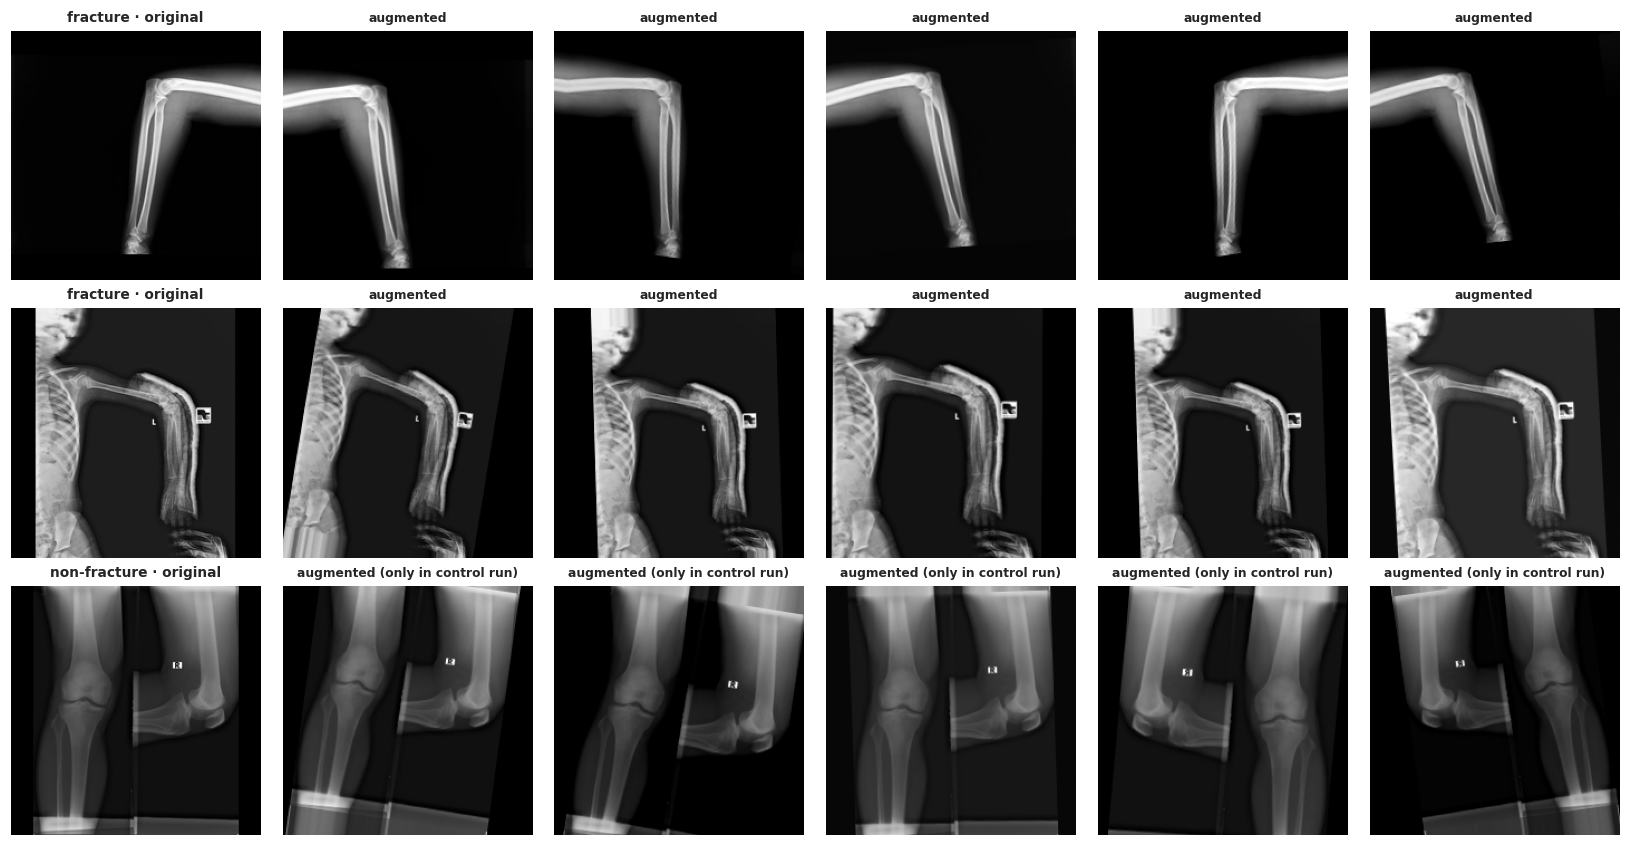

In [17]:
# Sanity check: what does each loader actually feed the model, and what does augmentation do?
chk = {}
for e in EXPERIMENTS:
    if e['key'] in ('bce', 'bce_minaug_bal'):
        ys = torch.cat([y for _, y in make_loader(e, 0)]); chk[e['label']] = float(ys.mean())
print('Share of fracture images seen per epoch ->', {k: f'{v:.1%}' for k, v in chk.items()})

rng_state = torch.get_rng_state(); torch.manual_seed(0)
pos_i = parts['train'].index[parts['train'].label == 1][:2].tolist() + parts['train'].index[parts['train'].label == 0][:1].tolist()
fig, axes = plt.subplots(len(pos_i), 6, figsize=(15, 2.6 * len(pos_i)), squeeze=False)
for row, i in zip(axes, pos_i):
    r = parts['train'].loc[i]; base = IMGS[r.path].float().unsqueeze(0) / 255.
    row[0].imshow(base[0], cmap='gray', vmin=0, vmax=1); row[0].set_title('fracture · original' if r.label else 'non-fracture · original', fontsize=9)
    for ax in row[1:]:
        ax.imshow(augment(base, MINORITY_STRENGTH)[0], cmap='gray', vmin=0, vmax=1); ax.set_title('augmented' if r.label else 'augmented (only in control run)', fontsize=8)
    for ax in row: ax.axis('off')
xfinish(fig, '16_minority_augmentation_preview', svg=False); torch.set_rng_state(rng_state)

## 15 · Train all experiments
Per run: AdamW + cosine schedule, early stopping on **validation AUPRC**, best epoch restored. After training, the decision threshold is chosen on the **validation** set (Youden's J), and a second operating point is set to reach ≥ `SENS_TARGET` sensitivity. Test and external predictions are stored, not used for any choice.

In [18]:
def thresholds_from_val(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    t_youden = float(thr[np.argmax(tpr - fpr)])
    ok = np.where(tpr >= SENS_TARGET)[0]
    return t_youden, float(thr[ok[0]]) if len(ok) else float(thr[-1])

def metrics_at(y, p, t):
    pred = (p >= t).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); prec = tp / max(tp + fp, 1)
    return dict(sensitivity=sens, specificity=spec, precision=prec, f1=2 * prec * sens / max(prec + sens, 1e-9), balanced_acc=(sens + spec) / 2)

RUNS = []
def run_experiment(exp, seed):
    set_seed(seed); model = make_model(); loss_fn = make_loss(exp['loss'])
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    use_amp = DEVICE.type == 'cuda'; scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    loader = make_loader(exp, seed); va = parts['validation']
    best, best_state, hist, bad = -1.0, None, [], 0
    for ep in range(1, EPOCHS + 1):
        model.train(); tl, n, pos = 0.0, 0, 0.0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE); opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp): logits = model(x)
            loss = loss_fn(logits.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); tl += float(loss) * len(y); n += len(y); pos += float(y.sum())
        sched.step()
        pv = predict(model, va); ap, auc = safe_ap(va.label.values, pv), safe_auc(va.label.values, pv)
        hist.append(dict(epoch=ep, train_loss=tl / n, pos_share=pos / n, val_auprc=ap, val_auroc=auc))
        if ap > best: best, best_state, bad = ap, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    ckpt = XOUT / 'ckpt' / f'{exp["key"]}_s{seed}.pt'; torch.save(best_state, ckpt)
    pv, pt = predict(model, va), predict(model, parts['test']); pe = predict(model, ext) if len(ext) else np.array([])
    t_y, t_s = thresholds_from_val(va.label.values, pv); yt = parts['test'].label.values
    r = dict(key=exp['key'], seed=seed, best_epoch=int(np.argmax([h['val_auprc'] for h in hist]) + 1), hist=pd.DataFrame(hist),
             p_val=pv, p_test=pt, p_ext=pe, thr_youden=t_y, thr_sens=t_s, ckpt=str(ckpt),
             val_auprc=safe_ap(va.label.values, pv), val_auroc=safe_auc(va.label.values, pv),
             test_auprc=safe_ap(yt, pt), test_auroc=safe_auc(yt, pt), test_brier=brier_score_loss(yt, pt))
    for tag, t in [('youden', t_y), ('sens90', t_s)]:
        for k, v in metrics_at(yt, pt, t).items(): r[f'test_{k}@{tag}'] = v
    return r

t0 = time.perf_counter()
for seed in SEEDS:
    for exp in EXPERIMENTS:
        t1 = time.perf_counter(); RUNS.append(run_experiment(exp, seed))
        r = RUNS[-1]; print(f'seed {seed} | {exp["label"]:<42} best epoch {r["best_epoch"]:>2} | val AUPRC {r["val_auprc"]:.3f} | {time.perf_counter() - t1:.0f}s')
print(f'Total training time: {(time.perf_counter() - t0) / 60:.1f} min')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 246MB/s]
/tmp/ipykernel_23/276414478.py:27: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  scaler.step(opt); scaler.update(); tl += float(loss) * len(y); n += len(y); pos += float(y.sum())


seed 42 | BCE (baseline)                             best epoch  7 | val AUPRC 0.757 | 72s
seed 42 | Weighted BCE                               best epoch 12 | val AUPRC 0.772 | 71s
seed 42 | Focal                                      best epoch 10 | val AUPRC 0.749 | 73s
seed 42 | BCE + minority aug + balanced sampler      best epoch  4 | val AUPRC 0.480 | 50s
seed 42 | Weighted BCE + minority aug                best epoch  1 | val AUPRC 0.477 | 32s
seed 42 | Focal + minority aug                       best epoch  6 | val AUPRC 0.506 | 61s
seed 42 | BCE + aug on all (control)                 best epoch 11 | val AUPRC 0.789 | 75s
Total training time: 7.2 min


## 16 · Results
Everything below is computed from the stored predictions. **Experiment choice is made on validation AUPRC**; test numbers are reported for all experiments so you can see the full picture, but they must not be used to pick a winner.

In [19]:
MET = ['val_auprc', 'val_auroc', 'test_auprc', 'test_auroc', 'test_brier',
       'test_sensitivity@youden', 'test_specificity@youden', 'test_f1@youden', 'test_balanced_acc@youden',
       'test_sensitivity@sens90', 'test_specificity@sens90']
runs_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ('hist', 'p_val', 'p_test', 'p_ext')} for r in RUNS])
mean_df = runs_df.groupby('key')[MET + ['best_epoch']].mean().reindex(KEYS)
sd_df = runs_df.groupby('key')[MET].std().reindex(KEYS)
show = mean_df.round(3).copy()
if len(SEEDS) > 1:
    for c in MET: show[c] = [f'{m:.3f} ± {s:.3f}' for m, s in zip(mean_df[c], sd_df[c])]
show.insert(0, 'experiment', [LABEL[k] for k in KEYS])
table = show.loc[mean_df.sort_values('val_auprc', ascending=False).index]
mean_df.reset_index().assign(experiment=lambda d: d.key.map(LABEL)).to_csv(XOUT / 'experiment_results.csv', index=False)
runs_df.to_csv(XOUT / 'experiment_runs_per_seed.csv', index=False)
print('Sorted by VALIDATION AUPRC (the selection criterion). Thresholds: Youden-J on validation / first threshold reaching', f'{SENS_TARGET:.0%} sensitivity on validation.')
display(table)
BEST = mean_df['val_auprc'].idxmax(); print(f'\nSelected on validation AUPRC: {LABEL[BEST]}')

# per-experiment ensemble over seeds (identical to the single run when SEEDS has one entry)
ens = {k: {s: np.mean([r[f'p_{s}'] for r in RUNS if r['key'] == k], axis=0) for s in ['val', 'test']} for k in KEYS}
yv, yt = parts['validation'].label.values, parts['test'].label.values; gt = parts['test'].group_id.values

Sorted by VALIDATION AUPRC (the selection criterion). Thresholds: Youden-J on validation / first threshold reaching 90% sensitivity on validation.


,experiment,val_auprc,val_auroc,test_auprc,test_auroc,test_brier,test_sensitivity@youden,test_specificity@youden,test_f1@youden,test_balanced_acc@youden,test_sensitivity@sens90,test_specificity@sens90,best_epoch
key,,,,,,,,,,,,,
bce_allaug,BCE + aug on all (control),0.789,0.909,0.761,0.899,0.079,0.721,0.906,0.649,0.814,0.902,0.712,11.0
wbce,Weighted BCE,0.772,0.913,0.687,0.869,0.099,0.762,0.834,0.576,0.798,0.885,0.680,12.0
bce,BCE (baseline),0.757,0.905,0.696,0.872,0.088,0.648,0.932,0.645,0.790,0.918,0.532,7.0
focal,Focal,0.749,0.898,0.699,0.878,0.081,0.689,0.895,0.613,0.792,0.885,0.636,10.0
focal_minaug,Focal + minority aug,0.506,0.776,0.301,0.680,0.149,0.574,0.661,0.340,0.617,0.869,0.290,6.0
bce_minaug_bal,BCE + minority aug + balanced sampler,0.480,0.724,0.297,0.685,0.158,0.492,0.814,0.396,0.653,0.893,0.188,4.0
wbce_minaug,Weighted BCE + minority aug,0.477,0.756,0.275,0.669,0.157,0.525,0.709,0.341,0.617,0.836,0.347,1.0



Selected on validation AUPRC: BCE + aug on all (control)


In [20]:
# Cluster bootstrap over image families (images of one family are not independent). Paired against the baseline.
def cluster_bootstrap(y, probs, groups, n_boot, seed=0):
    rng = np.random.default_rng(seed); ug = pd.unique(groups); idx = {g: np.where(groups == g)[0] for g in ug}
    res = {k: {'auroc': [], 'auprc': []} for k in probs}
    for _ in range(n_boot):
        samp = rng.integers(0, len(ug), len(ug)); ii = np.concatenate([idx[ug[s]] for s in samp])
        if len(np.unique(y[ii])) < 2: continue
        for k, p in probs.items():
            res[k]['auroc'].append(roc_auc_score(y[ii], p[ii])); res[k]['auprc'].append(average_precision_score(y[ii], p[ii]))
    return {k: {m: np.array(v) for m, v in d.items()} for k, d in res.items()}

boot = cluster_bootstrap(yt, {k: ens[k]['test'] for k in KEYS}, gt, N_BOOT)
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))
rows, drows = [], []
for k in KEYS:
    r = dict(key=k, experiment=LABEL[k])
    for m in ['auroc', 'auprc']:
        lo, hi = ci(boot[k][m]); r.update({m: roc_auc_score(yt, ens[k]['test']) if m == 'auroc' else average_precision_score(yt, ens[k]['test']), f'{m}_lo': lo, f'{m}_hi': hi})
        if k != 'bce':
            d = boot[k][m] - boot['bce'][m]; dl, dh = ci(d)
            drows.append(dict(experiment=LABEL[k], metric=m.upper(), delta_vs_baseline=float(np.mean(d)), ci_low=dl, ci_high=dh, ci_excludes_zero=bool(dl > 0 or dh < 0)))
    rows.append(r)
ci_df = pd.DataFrame(rows); diff_df = pd.DataFrame(drows)
ci_df.to_csv(XOUT / 'test_metrics_with_cluster_ci.csv', index=False); diff_df.to_csv(XOUT / 'paired_differences_vs_baseline.csv', index=False)
print(f'Test set (ensemble over seeds), 95% cluster-bootstrap CIs, {N_BOOT} resamples, {len(np.unique(gt))} test families:')
display(ci_df.round(3))
print('\nPaired differences against the BCE baseline (a gain is only credible if the interval excludes 0):')
display(diff_df.round(3))

Test set (ensemble over seeds), 95% cluster-bootstrap CIs, 1000 resamples, 711 test families:


,key,experiment,auroc,auroc_lo,auroc_hi,auprc,auprc_lo,auprc_hi
0,bce,BCE (baseline),0.872,0.830,0.911,0.696,0.614,0.776
1,wbce,Weighted BCE,0.869,0.823,0.909,0.687,0.600,0.767
2,focal,Focal,0.878,0.840,0.914,0.699,0.618,0.780
3,bce_minaug_bal,BCE + minority aug + balanced sampler,0.685,0.630,0.737,0.297,0.232,0.374
4,wbce_minaug,Weighted BCE + minority aug,0.669,0.615,0.723,0.275,0.216,0.357
5,focal_minaug,Focal + minority aug,0.680,0.625,0.736,0.301,0.235,0.386
6,bce_allaug,BCE + aug on all (control),0.899,0.861,0.933,0.761,0.689,0.827



Paired differences against the BCE baseline (a gain is only credible if the interval excludes 0):


,experiment,metric,delta_vs_baseline,ci_low,ci_high,ci_excludes_zero
0,Weighted BCE,AUROC,-0.003,-0.032,0.026,False
1,Weighted BCE,AUPRC,-0.010,-0.048,0.027,False
2,Focal,AUROC,0.006,-0.017,0.030,False
3,Focal,AUPRC,0.002,-0.037,0.041,False
4,BCE + minority aug + balanced sampler,AUROC,-0.189,-0.242,-0.138,True
5,BCE + minority aug + balanced sampler,AUPRC,-0.396,-0.481,-0.305,True
6,Weighted BCE + minority aug,AUROC,-0.204,-0.259,-0.147,True
7,Weighted BCE + minority aug,AUPRC,-0.417,-0.497,-0.330,True
8,Focal + minority aug,AUROC,-0.193,-0.251,-0.137,True
9,Focal + minority aug,AUPRC,-0.392,-0.476,-0.300,True


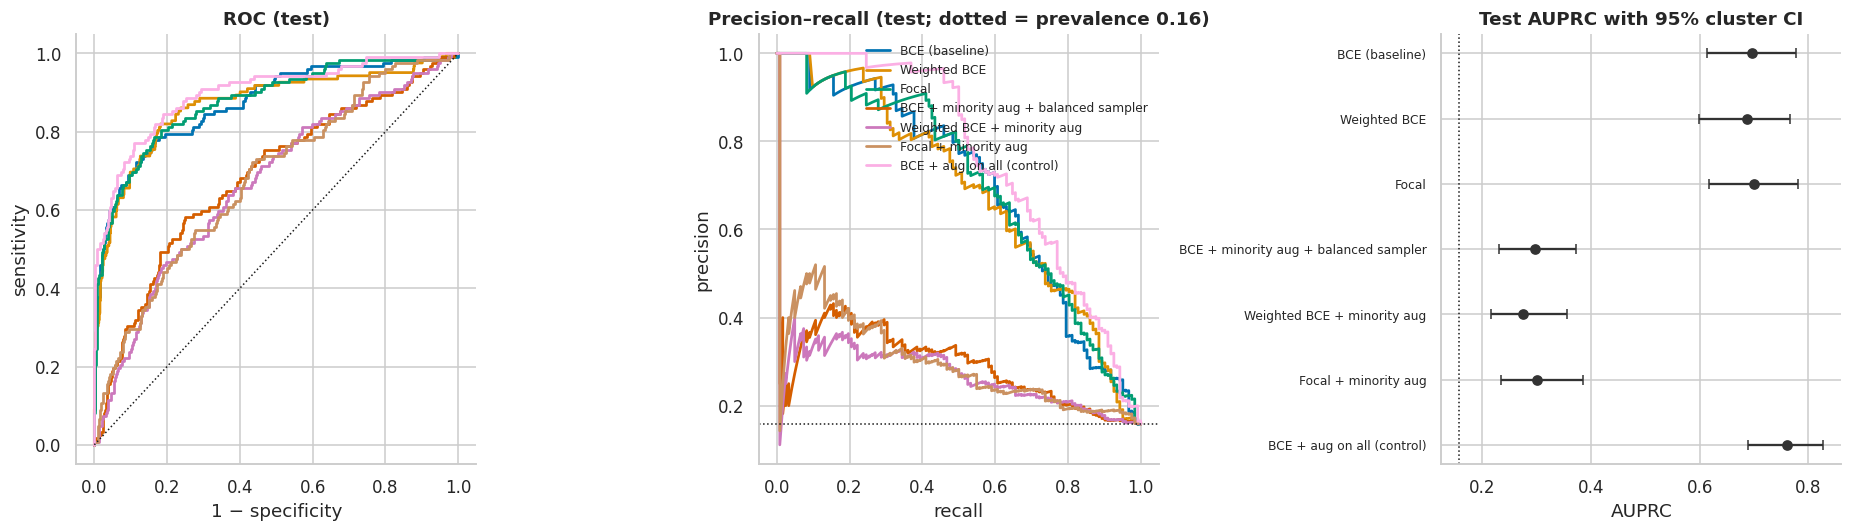

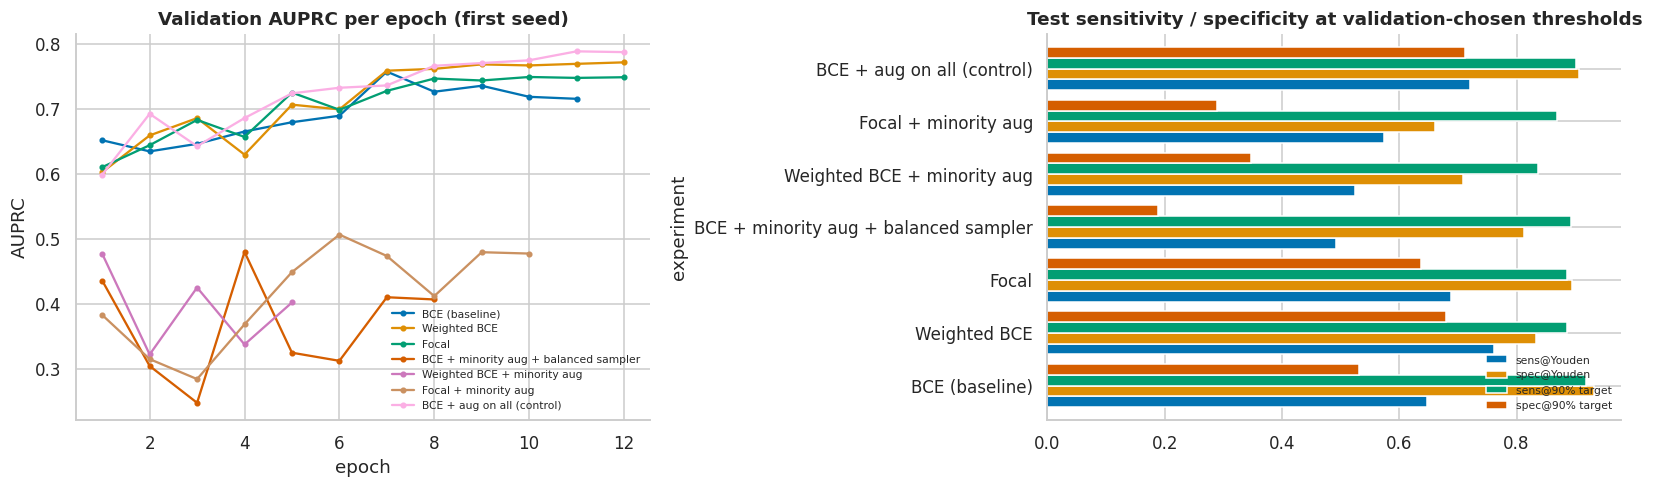

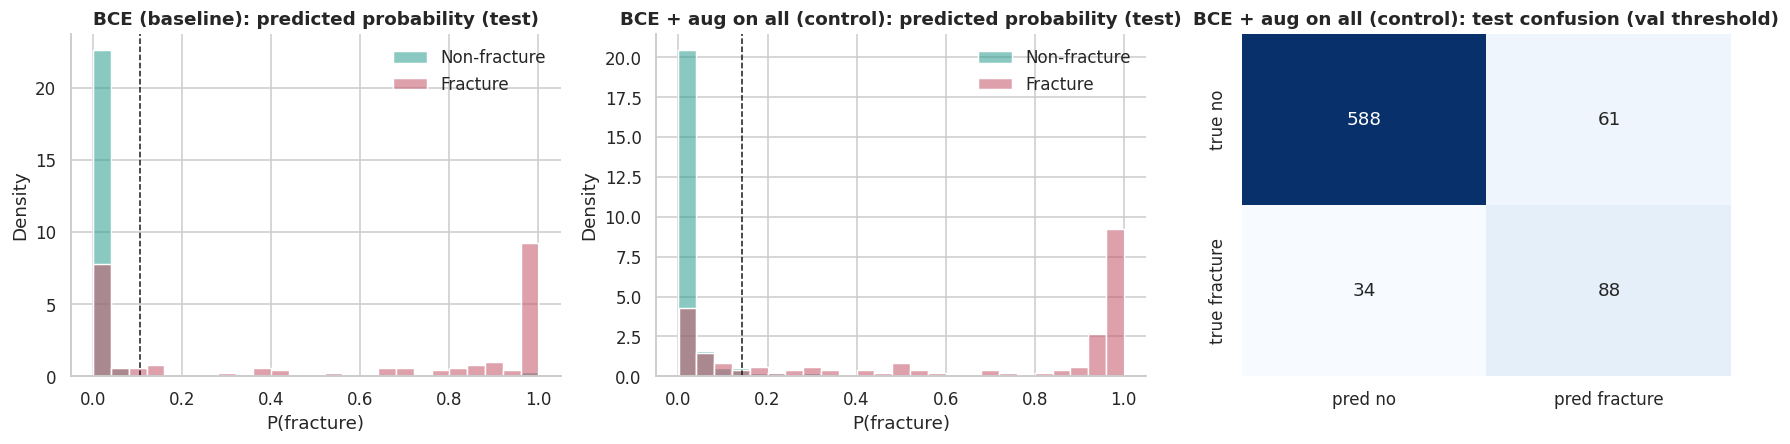

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for k in KEYS:
    fpr, tpr, _ = roc_curve(yt, ens[k]['test']); axes[0].plot(fpr, tpr, color=PAL[k], lw=1.8, label=LABEL[k])
    pr, rc, _ = precision_recall_curve(yt, ens[k]['test']); axes[1].plot(rc, pr, color=PAL[k], lw=1.8, label=LABEL[k])
axes[0].plot([0, 1], [0, 1], 'k:', lw=1); axes[0].set(title='ROC (test)', xlabel='1 − specificity', ylabel='sensitivity')
axes[1].axhline(yt.mean(), color='k', ls=':', lw=1); axes[1].set(title=f'Precision–recall (test; dotted = prevalence {yt.mean():.2f})', xlabel='recall', ylabel='precision')
axes[1].legend(frameon=False, fontsize=8, loc='upper right')
y_pos = np.arange(len(KEYS))[::-1]
axes[2].errorbar(ci_df.auprc, y_pos, xerr=[ci_df.auprc - ci_df.auprc_lo, ci_df.auprc_hi - ci_df.auprc], fmt='o', color='#333', capsize=3)
axes[2].set_yticks(y_pos); axes[2].set_yticklabels([LABEL[k] for k in KEYS], fontsize=8); axes[2].axvline(yt.mean(), color='k', ls=':', lw=1)
axes[2].set(title='Test AUPRC with 95% cluster CI', xlabel='AUPRC')
xfinish(fig, '17_roc_pr_ci')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for k in KEYS:
    h = [r['hist'] for r in RUNS if r['key'] == k][0]; axes[0].plot(h.epoch, h.val_auprc, marker='o', ms=3, color=PAL[k], label=LABEL[k])
axes[0].set(title='Validation AUPRC per epoch (first seed)', xlabel='epoch', ylabel='AUPRC'); axes[0].legend(frameon=False, fontsize=7)
op = pd.DataFrame({'experiment': [LABEL[k] for k in KEYS], 'sens@Youden': mean_df['test_sensitivity@youden'].values, 'spec@Youden': mean_df['test_specificity@youden'].values,
                   f'sens@{SENS_TARGET:.0%} target': mean_df['test_sensitivity@sens90'].values, f'spec@{SENS_TARGET:.0%} target': mean_df['test_specificity@sens90'].values})
op.set_index('experiment').plot.barh(ax=axes[1], width=.82); axes[1].set(title='Test sensitivity / specificity at validation-chosen thresholds', xlabel=''); axes[1].legend(frameon=False, fontsize=7, loc='lower right')
xfinish(fig, '18_training_and_operating_points')

best_t = np.mean([r['thr_youden'] for r in RUNS if r['key'] == BEST]); base_t = np.mean([r['thr_youden'] for r in RUNS if r['key'] == 'bce'])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, k, t in [(axes[0], 'bce', base_t), (axes[1], BEST, best_t)]:
    for c, col in [(0, '#2A9D8F'), (1, '#C45566')]: sns.histplot(ens[k]['test'][yt == c], bins=25, stat='density', color=col, alpha=.55, label=['Non-fracture', 'Fracture'][c], ax=ax)
    ax.axvline(t, color='k', ls='--', lw=1); ax.set(title=f'{LABEL[k]}: predicted probability (test)', xlabel='P(fracture)'); ax.legend(frameon=False)
cm = confusion_matrix(yt, (ens[BEST]['test'] >= best_t).astype(int), labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['pred no', 'pred fracture'], yticklabels=['true no', 'true fracture'], ax=axes[2])
axes[2].set_title(f'{LABEL[BEST]}: test confusion (val threshold)'); xfinish(fig, '19_probabilities_and_confusion')

## 17 · External evaluation (HBFMID originals)
HBFMID is a different source and modality mix, kept completely out of training and model selection. If its labelled images are all fractures, only **sensitivity** is meaningful (no AUROC/specificity). Thresholds come from the *validation* set of FracAtlas.

In [22]:
if not len(ext):
    print('No external images in the manifest (HBFMID labels were unavailable); skipped.')
else:
    ye = ext.label.values; rows = []
    def wilson(k, n, z=1.96):
        if n == 0: return (np.nan, np.nan)
        ph = k / n; ctr = (ph + z * z / (2 * n)) / (1 + z * z / n); h = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        return ctr - h, ctr + h
    for k in KEYS:
        pe = np.mean([r['p_ext'] for r in RUNS if r['key'] == k], axis=0)
        ty = np.mean([r['thr_youden'] for r in RUNS if r['key'] == k]); ts = np.mean([r['thr_sens'] for r in RUNS if r['key'] == k])
        hit = int((pe[ye == 1] >= ty).sum()); lo, hi = wilson(hit, int((ye == 1).sum()))
        row = dict(experiment=LABEL[k], n=len(ye), fractured=int(ye.sum()), healthy=int((ye == 0).sum()), sensitivity_youden=hit / max(int((ye == 1).sum()), 1),
                   sens_ci_low=lo, sens_ci_high=hi, sensitivity_at_sens90_thr=float((pe[ye == 1] >= ts).mean()),
                   specificity_youden=float((pe[ye == 0] < ty).mean()) if (ye == 0).any() else np.nan)
        if len(np.unique(ye)) == 2: row.update(auroc=roc_auc_score(ye, pe), auprc=average_precision_score(ye, pe))
        rows.append(row)
    ext_df = pd.DataFrame(rows); ext_df.to_csv(XOUT / 'external_results.csv', index=False); display(ext_df.round(3))
    if (ye == 0).sum() < 30: print(f'External set has only {int((ye == 0).sum())} healthy images: report sensitivity (with its CI); ignore specificity/AUROC.')
    if len(ye) < 30: print(f'NOTE: only {len(ye)} external images; treat as a sanity check, not evidence.')

,experiment,n,fractured,healthy,sensitivity_youden,sens_ci_low,sens_ci_high,sensitivity_at_sens90_thr,specificity_youden,auroc,auprc
0,BCE (baseline),161,151,10,0.397,0.323,0.477,0.861,0.9,0.666,0.966
1,Weighted BCE,161,151,10,0.576,0.496,0.652,0.728,1.0,0.788,0.984
2,Focal,161,151,10,0.351,0.279,0.430,0.788,1.0,0.743,0.979
3,BCE + minority aug + balanced sampler,161,151,10,1.000,0.975,1.000,1.000,0.0,0.581,0.950
4,Weighted BCE + minority aug,161,151,10,1.000,0.975,1.000,1.000,0.0,0.434,0.928
5,Focal + minority aug,161,151,10,1.000,0.975,1.000,1.000,0.0,0.616,0.968
6,BCE + aug on all (control),161,151,10,0.556,0.477,0.633,0.801,0.8,0.721,0.973


External set has only 10 healthy images: report sensitivity (with its CI); ignore specificity/AUROC.


## 18 · Findings and exports

In [23]:
nb = diff_df[diff_df.metric == 'AUPRC'].set_index('experiment')
lines = [f'Validation-selected best: {LABEL[BEST]} (val AUPRC {mean_df.loc[BEST, "val_auprc"]:.3f}).']
b = ci_df.set_index('key').loc[BEST]
lines.append(f'Test AUPRC {b.auprc:.3f} (95% CI {b.auprc_lo:.3f}–{b.auprc_hi:.3f}); baseline {ci_df.set_index("key").loc["bce", "auprc"]:.3f}; prevalence {yt.mean():.3f}.')
if BEST != 'bce':
    d = nb.loc[LABEL[BEST]]
    lines.append(f'Paired AUPRC change vs baseline: {d.delta_vs_baseline:+.3f} (95% CI {d.ci_low:+.3f} to {d.ci_high:+.3f}) -> '
                 + ('interval excludes 0.' if d.ci_excludes_zero else 'interval includes 0: NOT distinguishable from the baseline on this test set.'))
sig = diff_df[(diff_df.metric == 'AUPRC') & diff_df.ci_excludes_zero & (diff_df.delta_vs_baseline > 0)].experiment.tolist()
if yt.sum() < 50: lines.append('Credibility of gains NOT assessed: too few fractured test images for the bootstrap to be trusted.')
else: lines.append('Experiments with a credible AUPRC gain over baseline: ' + (', '.join(sig) if sig else 'none (differences are within noise).'))
ctrl = diff_df[(diff_df.metric == 'AUPRC') & (diff_df.experiment == LABEL['bce_allaug'])]
if len(ctrl): lines.append(f'Control (augment all classes) change: {ctrl.delta_vs_baseline.iloc[0]:+.3f} AUPRC; compare with the minority-only runs to see whether class-conditional augmentation matters.')
if len(SEEDS) == 1: lines.append('Only one seed was run: repeat with SEEDS=[42, 123, 2026] before reporting.')
if yt.sum() < 50: lines.append(f'Only {int(yt.sum())} fractured test images: intervals are wide; prefer family-grouped cross-validation for the final claim.')
print('\n'.join('• ' + l for l in lines))
(XOUT / 'findings.txt').write_text('\n'.join(lines))

pred = parts['test'][['path', 'group_id', 'label']].copy()
for k in KEYS: pred[f'p_{k}'] = ens[k]['test']
pred.to_csv(XOUT / 'test_predictions.csv', index=False)
best_run = max((r for r in RUNS if r['key'] == BEST), key=lambda r: r['val_auprc'])
shutil.copy(best_run['ckpt'], XOUT / 'best_model.pt')
for r in RUNS:
    if r['ckpt'] != best_run['ckpt']: Path(r['ckpt']).unlink(missing_ok=True)
(XOUT / 'experiment_config.json').write_text(json.dumps(dict(backbone=BACKBONE, pretrained=PRETRAINED, img_size=IMG_SIZE, epochs=EPOCHS, patience=PATIENCE,
    batch=BATCH, lr=LR, weight_decay=WD, seeds=SEEDS, focal_gamma=FOCAL_GAMMA, focal_alpha=round(1 - PREV, 4), pos_weight=round(n_neg / n_pos, 4),
    minority_strength=MINORITY_STRENGTH, mean=MEAN, std=STD, selected=BEST, selected_label=LABEL[BEST], experiments=EXPERIMENTS), indent=2))
print('\nSaved to', XOUT, ':', sorted(p.name for p in XOUT.iterdir() if p.is_file()))

• Validation-selected best: BCE + aug on all (control) (val AUPRC 0.789).
• Test AUPRC 0.761 (95% CI 0.689–0.827); baseline 0.696; prevalence 0.158.
• Paired AUPRC change vs baseline: +0.063 (95% CI +0.015 to +0.113) -> interval excludes 0.
• Experiments with a credible AUPRC gain over baseline: BCE + aug on all (control)
• Control (augment all classes) change: +0.063 AUPRC; compare with the minority-only runs to see whether class-conditional augmentation matters.
• Only one seed was run: repeat with SEEDS=[42, 123, 2026] before reporting.

Saved to /kaggle/working/fracture_experiments : ['best_model.pt', 'experiment_config.json', 'experiment_results.csv', 'experiment_runs_per_seed.csv', 'external_results.csv', 'findings.txt', 'paired_differences_vs_baseline.csv', 'test_metrics_with_cluster_ci.csv', 'test_predictions.csv']
